<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

### Procesamiento de Lenguaje Natural I — CEIA FIUBA
# **Desafío 2 — Custom embeddings con Gensim**

**Alumno:** Jaime Ricardo Pinzon Aparicio (jaripia64@gmail.com) · Cohorte 26Co2026 (a264b26)

**Corpus propio:** tres novelas de **Julio Verne** en español, descargadas de
[textos.info](https://www.textos.info/) (fuente sugerida en la clase 2): *La vuelta al mundo en
80 días*, *Viaje al centro de la Tierra* y *Veinte mil leguas de viaje submarino*.

**Contenido:**
1. Descarga y preprocesamiento del corpus (oraciones como documentos, tokenización).
2. Entrenamiento de embeddings propios con **Word2Vec (skipgram)** de Gensim, con seguimiento
   del loss por época.
3. Ensayos: términos más y menos similares, analogías, término fuera de vocabulario.
4. **Sustento experimental de los hiperparámetros**: comparación skipgram vs. CBOW y ventana
   chica vs. grande sobre las mismas palabras sonda.
5. Reducción de dimensionalidad con t-SNE, elección de `MAX_WORDS`, visualización 2D/3D e
   interpretación de los grupos de palabras.

> Cada experimento está acompañado de su interpretación, cada decisión (corpus, preprocesamiento,
> hiperparámetros) está justificada en el texto, y **toda cifra sobre este corpus citada en los
> análisis proviene de un output visible del notebook** (las dos cifras del ejemplo de clase —
> 1.846 documentos y 445 palabras — se citan de la plantilla de la cátedra).

## Elección del corpus

La consigna pide un **corpus propio**. Elegimos tres novelas de Julio Verne en español por tres
razones:

1. **Volumen suficiente.** En el ejemplo de clase (canciones de los Beatles) el vocabulario final
   con `min_count=5` quedaba en apenas 445 palabras. Word2Vec aprende de co-ocurrencias: con poco
   texto, los vecinos más cercanos son ruidosos. Tres novelas juntas superan el millón y medio
   de caracteres (medido más abajo), muy por encima del ejemplo de clase.
2. **Un universo temático coherente pero variado.** Las tres novelas comparten autor, época y
   género (viaje/aventura/ciencia), así que esperamos que emerjan campos semánticos
   identificables: navegación, geografía, tiempo/números, personajes. Esto hace interpretable la
   visualización — el objetivo central de la consigna.
3. **Es una de las fuentes sugeridas en la clase 2** (textos.info), y se descarga con
   HTML + BeautifulSoup, así que el notebook es reproducible sin archivos locales.

🔑 **Idea que guía todo el trabajo** (clase 2): los embeddings toman la forma del **uso** que el
corpus hace de las palabras. Los vecinos de "capitán" en Verne no serán los de un corpus de
noticias: eso es exactamente lo que queremos observar.

In [1]:
import os
import re
import random
import multiprocessing
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from gensim.models import Word2Vec
except ImportError:
    %pip install -q gensim
    from gensim.models import Word2Vec

import gensim
from gensim.utils import simple_preprocess
from gensim.models.callbacks import CallbackAny2Vec

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("gensim:", gensim.__version__)
print("numpy: ", np.__version__)

gensim: 4.4.0
numpy:  1.26.2


### Datos: descarga con caché local

Descargamos cada novela desde textos.info (la página `/ebook` contiene el libro completo), la
parseamos con BeautifulSoup extrayendo los párrafos `<p>` — igual que el material de la cátedra —
y la guardamos en `corpus_verne/` para no volver a descargarla en corridas siguientes (la
consigna exige que el notebook corra de inicio a fin: la caché hace la corrida repetible aunque
el sitio esté caído).

In [2]:
try:
    import bs4 as bs
except ImportError:
    %pip install -q beautifulsoup4
    import bs4 as bs

LIBROS = {
    "la_vuelta_al_mundo": "https://www.textos.info/julio-verne/la-vuelta-al-mundo-en-80-dias/ebook",
    "viaje_centro_tierra": "https://www.textos.info/julio-verne/viaje-al-centro-de-la-tierra/ebook",
    "veinte_mil_leguas": "https://www.textos.info/julio-verne/veinte-mil-leguas-de-viaje-submarino/ebook",
}

os.makedirs("corpus_verne", exist_ok=True)

def descargar_libro(nombre, url):
    ruta = os.path.join("corpus_verne", nombre + ".txt")
    if os.path.exists(ruta):
        with open(ruta, encoding="utf-8") as fp:
            return fp.read()
    raw_html = urllib.request.urlopen(url, timeout=60).read()
    soup = bs.BeautifulSoup(raw_html, "html.parser")
    texto = " ".join(p.text for p in soup.find_all("p"))
    with open(ruta, "w", encoding="utf-8") as fp:
        fp.write(texto)
    return texto

textos = {nombre: descargar_libro(nombre, url) for nombre, url in LIBROS.items()}

for nombre, texto in textos.items():
    print(f"{nombre:22s}: {len(texto):>9,} caracteres")
print(f"{'TOTAL':22s}: {sum(len(t) for t in textos.values()):>9,} caracteres")
print("\nInicio de 'La vuelta al mundo':\n", textos["la_vuelta_al_mundo"][:300])

la_vuelta_al_mundo    :   399,770 caracteres
viaje_centro_tierra   :   432,971 caracteres
veinte_mil_leguas     :   855,955 caracteres
TOTAL                 : 1,688,696 caracteres

Inicio de 'La vuelta al mundo':
  En el año 1872, la casa número 7 de Saville-Row, Burlington Gardens 

—donde murió Sheridan en 1814— estaba habitada por Phileas Fogg, quien a

 pesar de que parecía haber tomado el partido de no hacer nada que 

pudiese llamar la atención, era uno de los miembros más notables y 

singulares del Re


### 1 - Preprocesamiento

Decisiones, con su justificación:

- **Documento = oración.** Igual que en el ejemplo de clase (cada línea de canción era un
  documento), acá segmentamos por `. ! ? … ;`. Word2Vec recorta las ventanas de contexto en los
  bordes de cada documento: segmentar por oración evita que la última palabra de un capítulo
  "co-ocurra" con la primera del siguiente.
- **Tokenización con `gensim.utils.simple_preprocess(deacc=False)`**: pasa a minúsculas, separa
  por no-alfanuméricos y descarta tokens de 1 carácter. Usamos `deacc=False` para **conservar las
  tildes**: en español "paso" y "pasó" son formas distintas y queremos que el embedding las
  distinga. Efectos colaterales que aceptamos conscientemente: **descarta las palabras de una letra**, entre ellas las muy frecuentes "y", "a", "o" y "e" (se ve en el primer ejemplo: "quien pesar de"), así que esas palabras funcionales no participan como contexto; **descarta los números
  escritos con dígitos** (el "1872" y el "7" del inicio desaparecen en el primer ejemplo de abajo;
  los números escritos con letras sí quedan) y **descarta tokens de más de 15 caracteres**
  (`max_len=15`; la celda siguiente cuenta cuántos se pierden). Tampoco normalizamos variantes
  ortográficas del texto fuente (p. ej. `índico`/`indico`), que quedan como tipos distintos. (La plantilla usaba `text_to_word_sequence` de Keras/TensorFlow; la clase aclara que
  cualquier tokenizador razonable sirve — NLTK, spaCy, etc.)
- **No removemos stopwords.** A diferencia de TF-IDF (Desafío 1), Word2Vec usa las palabras
  funcionales como **contexto** para posicionar a las demás; además el parámetro `sample`
  subsamplea automáticamente las palabras muy frecuentes durante el entrenamiento. Las stopwords
  se filtran después, solo para la **visualización**.
- **Filtramos oraciones de menos de 3 tokens**: una "oración" de 1–2 palabras (restos de
  diálogos: "—sí", "—¿y bien?") no aporta ventana de contexto útil.

In [3]:
# Segmentación en oraciones y tokenización
texto_completo = " ".join(textos.values())
oraciones_crudas = re.split(r"[.!?…;]+", texto_completo)

sentence_tokens = []
for oracion in oraciones_crudas:
    tokens = simple_preprocess(oracion, deacc=False)
    if len(tokens) >= 3:
        sentence_tokens.append(tokens)

n_tokens = sum(len(s) for s in sentence_tokens)
print(f"Oraciones crudas:                  {len(oraciones_crudas):>9,}")
print(f"Documentos (oraciones >= 3 tokens): {len(sentence_tokens):>9,}")
print(f"Tokens totales:                    {n_tokens:>9,}")
print(f"Tokens únicos (sin min_count):     {len(set(t for s in sentence_tokens for t in s)):>9,}")
print("\nEjemplos:")
for s in sentence_tokens[:3]:
    print(" ", s)

# Costo del límite max_len=15 de simple_preprocess
largas = re.findall(r"[^\W\d_]{16,}", texto_completo.lower())
print(f"\nTokens de más de 15 letras descartados: {len(largas):,} "
      f"({len(largas) / n_tokens:.2%} del total) — ej.: {sorted(set(largas))[:5]}")

Oraciones crudas:                     18,785
Documentos (oraciones >= 3 tokens):    17,078
Tokens totales:                      258,197
Tokens únicos (sin min_count):        24,386

Ejemplos:
  ['en', 'el', 'año', 'la', 'casa', 'número', 'de', 'saville', 'row', 'burlington', 'gardens', 'donde', 'murió', 'sheridan', 'en', 'estaba', 'habitada', 'por', 'phileas', 'fogg', 'quien', 'pesar', 'de', 'que', 'parecía', 'haber', 'tomado', 'el', 'partido', 'de', 'no', 'hacer', 'nada', 'que', 'pudiese', 'llamar', 'la', 'atención', 'era', 'uno', 'de', 'los', 'miembros', 'más', 'notables', 'singulares', 'del', 'reformclub', 'de', 'londres']
  ['por', 'consiguiente', 'phileas', 'fogg', 'personaje', 'enigmático', 'del', 'cual', 'sólo', 'se', 'sabía', 'que', 'era', 'un', 'hombre', 'muy', 'galante', 'de', 'los', 'más', 'cumplidos', 'gentlemen', 'de', 'la', 'alta', 'sociedad', 'inglesa', 'sucedía', 'uno', 'de', 'los', 'más', 'grandes', 'oradores', 'que', 'honran', 'inglaterra']
  ['decíase', 'que', 'se', 


Tokens de más de 15 letras descartados: 205 (0.08% del total) — ej.: ['acondicionamiento', 'administraciones', 'alternativamente', 'anfractuosidades', 'aprovisionamiento']


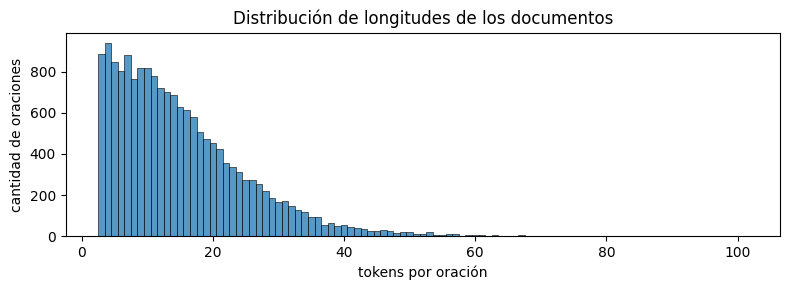

mediana = 13 tokens | p90 = 29 | máx = 101
oraciones con < 11 tokens (no entra una ventana completa de 5 + 1 + 5): 40% | % de TOKENS que están en esas oraciones: 17%


In [4]:
# Distribución de longitudes de los documentos
longitudes = [len(s) for s in sentence_tokens]
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(longitudes, discrete=True, ax=ax)
ax.set_xlabel("tokens por oración")
ax.set_ylabel("cantidad de oraciones")
ax.set_title("Distribución de longitudes de los documentos")
plt.tight_layout(); plt.show()
print(f"mediana = {np.median(longitudes):.0f} tokens | p90 = {np.percentile(longitudes, 90):.0f} | máx = {max(longitudes)}")
L = np.array(longitudes)
print(f"oraciones con < 11 tokens (no entra una ventana completa de 5 + 1 + 5): {np.mean(L < 11):.0%} "
      f"| % de TOKENS que están en esas oraciones: {L[L < 11].sum() / L.sum():.0%}")

**Lectura de los números:** el corpus combinado tiene **1.688.696 caracteres** que, tras
segmentar y filtrar, quedan en **17.078 documentos** y **258.197 tokens** (24.386 únicos antes
de aplicar `min_count`). La mediana es de **13 tokens por oración** y el p90 de **29**. Una ventana completa (5 a cada
lado + la palabra central) necesita 11 tokens, y el **40% de las oraciones** tiene menos. El
recorte es aceptable por dos razones medidas o documentadas: esas oraciones cortas contienen solo
el **17% de los tokens**, y gensim ya achica la ventana efectiva al azar entre 1 y `window` en cada
posición, así que la mayoría de los pares de entrenamiento son cercanos de todos modos.
El tamaño también valida la decisión de usar tres novelas: **17.078 documentos** contra los
1.846 del ejemplo de clase (canciones de los Beatles), que con el mismo `min_count=5` terminaba
con un vocabulario de apenas 445 palabras.

### 2 - Creación del modelo (Word2Vec)

Configuración **base**, parámetro por parámetro:

- **`sg=1` (skipgram):** predice el contexto a partir de la palabra central. Es la opción
  recomendada en clase para corpus chicos/medianos porque genera más pares de entrenamiento por
  oración que CBOW y representa mejor las palabras poco frecuentes. *(En la sección 5 lo
  comparamos empíricamente contra CBOW en este mismo corpus.)*
- **`vector_size=150`:** valor intermedio entre los 300 de la plantilla y las dimensiones bajas
  típicas de corpus chicos (nuestro vocabulario efectivo es de ~5.200 palabras). *(Sección 5:
  comparación contra 50 y 300.)*
- **`window=5`:** ventana intermedia. Captura relaciones sintagmáticas y temáticas sin mezclar
  temas lejanos. *(Sección 5: comparación window=2 vs. window=10.)*
- **`min_count=5`:** con menos de 5 apariciones no hay evidencia estadística para un vector
  confiable; es el valor del material de clase. *(Por convención: no lo verificamos
  experimentalmente, igual que `sample` y `negative`.)*
- **`negative=20`:** negative sampling con 20 muestras, como en la plantilla; valor alto
  recomendado para corpus chicos (Mikolov et al. sugieren 5–20).
- **`sample=1e-4`:** subsampleo de palabras muy frecuentes ("de", "que", "la"...), para que no
  dominen las ventanas de contexto.
- **`workers=1` + `seed=SEED`:** con un solo worker se elimina la principal fuente de
  no-determinismo (con multithreading el orden de los ejemplos — y el resultado — varía entre
  corridas). Pagamos tiempo de cómputo a cambio de poder citar números exactos. La documentación de gensim advierte que, entre intérpretes, también puede influir
  `PYTHONHASHSEED`; en otro entorno (p. ej. Colab, con otras versiones de numpy/gensim) los
  vecinos podrían variar levemente y los números citados deberían re-leerse de los outputs.
- **`epochs=40`:** no lo decidimos mirando el loss de gensim (que tiene artefactos numéricos,
  ver la sección 3), sino comparando 20 contra 40 épocas en la sección 5 con métricas sobre los
  vectores. Anticipamos el resultado: la evidencia es mixta (20 épocas gana en palabras
  frecuentes y 40 en palabras raras), y la decisión y su costo se discuten allí.

In [5]:
# Callback para informar el loss por época (gensim no lo hace por defecto).
# Nota: get_latest_training_loss() devuelve el loss ACUMULADO desde el inicio del train,
# por eso informamos la diferencia contra la época anterior (igual que en el material de clase).
class LossPorEpoca(CallbackAny2Vec):
    def __init__(self):
        self.epoch = 0
        self.loss_prev = 0.0
        self.historia = []   # loss de cada época
        self.acumulado = []  # loss acumulado que devuelve gensim al final de cada época

    def on_epoch_end(self, model):
        loss_acum = model.get_latest_training_loss()
        loss_epoca = loss_acum - self.loss_prev
        self.historia.append(loss_epoca)
        self.acumulado.append(loss_acum)
        if self.epoch == 0 or (self.epoch + 1) % 5 == 0:
            print(f"época {self.epoch + 1:>2d} | loss de la época: {loss_epoca:,.0f}")
        self.loss_prev = loss_acum
        self.epoch += 1


def crear_w2v(**kwargs):
    params = dict(min_count=5, window=5, vector_size=150, negative=20,
                  sample=1e-4, workers=1, seed=SEED, sg=1)
    params.update(kwargs)
    return Word2Vec(**params)

w2v_model = crear_w2v()
w2v_model.build_vocab(sentence_tokens)
print("Docs en el corpus:        ", w2v_model.corpus_count)
print("Vocabulario (min_count=5):", len(w2v_model.wv.index_to_key))


Docs en el corpus:         17078
Vocabulario (min_count=5): 5242


### 3 - Entrenamiento

época  1 | loss de la época: 1,945,892


época  5 | loss de la época: 1,189,908


época 10 | loss de la época: 1,104,001


época 15 | loss de la época: 999,216


época 20 | loss de la época: 927,122


época 25 | loss de la época: 864,334


época 30 | loss de la época: 829,506


época 35 | loss de la época: 719,788


época 40 | loss de la época: 704,560
tiempo de entrenamiento del modelo base: 83 s
caída relativa época 1 → 5:   39%
caída relativa época 30 → 40: 15%
mayores caídas entre épocas consecutivas: ép. 1→2: 641,655, ép. 33→34: 67,050, ép. 3→4: 54,942, ép. 2→3: 44,624
el acumulado cruza 2^24 = 16,777,216 al final de la época 14 (caída de la época 14→15: 40,068)
el acumulado cruza 2^25 = 33,554,432 al final de la época 33 (caída de la época 33→34: 67,050)


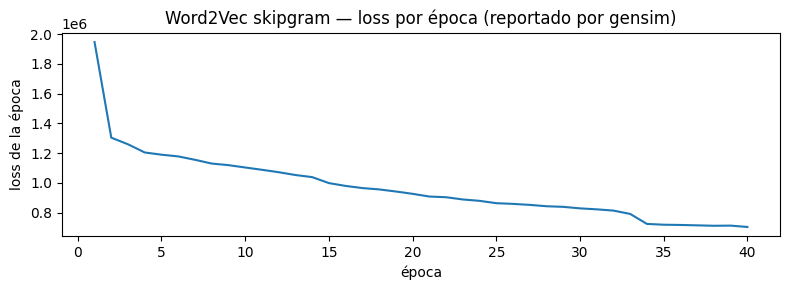

In [6]:
import time

callback_base = LossPorEpoca()
t0_base = time.time()
w2v_model.train(sentence_tokens,
                total_examples=w2v_model.corpus_count,
                epochs=40,
                compute_loss=True,
                callbacks=[callback_base])
tiempo_base = time.time() - t0_base
print(f"tiempo de entrenamiento del modelo base: {tiempo_base:.0f} s")

h = callback_base.historia
print(f"caída relativa época 1 → 5:   {1 - h[4] / h[0]:.0%}")
print(f"caída relativa época 30 → 40: {1 - h[39] / h[29]:.0%}")
saltos = sorted(((i, h[i - 1] - h[i]) for i in range(1, len(h))), key=lambda x: -x[1])[:4]
print("mayores caídas entre épocas consecutivas:",
      ", ".join(f"ép. {i}→{i + 1}: {d:,.0f}" for i, d in saltos))

# Diagnóstico de los escalones: gensim acumula el loss en float32. Por encima de 2^24 la
# separación entre floats representables pasa a ser 2, por encima de 2^25 pasa a ser 4, etc.,
# y los incrementos pequeños se redondean hacia abajo: el loss "por época" cae en escalón
# cada vez que el acumulado cruza una potencia de 2, sin que cambie el aprendizaje.
acum = callback_base.acumulado
for pot in (24, 25):
    cruce = next((i for i, a in enumerate(acum) if a >= 2 ** pot), None)
    if cruce is not None:
        print(f"el acumulado cruza 2^{pot} = {2 ** pot:,} al final de la época {cruce + 1} "
              f"(caída de la época {cruce + 1}→{cruce + 2}: {h[cruce] - h[cruce + 1]:,.0f})")

fig, ax = plt.subplots(figsize=(8, 3))
sns.lineplot(x=range(1, len(h) + 1), y=h, ax=ax)
ax.set_xlabel("época"); ax.set_ylabel("loss de la época")
ax.set_title("Word2Vec skipgram — loss por época (reportado por gensim)")
plt.tight_layout(); plt.show()


**Lectura de la curva:** la forma general es la esperada: una caída brusca al principio
(**−39% entre las épocas 1 y 5**, casi toda en el salto 1→2) y luego un descenso lento.

**Los dos escalones de la curva (épocas 14→15 y 33→34) son un artefacto numérico, no
aprendizaje.** La celda anterior muestra que caen justo en las épocas en que el loss **acumulado** de gensim
cruza **2²⁴ (época 14)** y **2²⁵ (época 33)**. El de la época 33→34 es la segunda mayor caída de
toda la curva (67.050). El de la 14→15 es más chico (40.068, menor que la caída 3→4), pero se ve
como un quiebre en el gráfico. gensim acumula el loss en `float32`: por encima de 2²⁴ la
distancia entre números representables pasa a 2 y por encima de 2²⁵ a 4. Cada suma se redondea
al representable más cercano, y los incrementos chicos pierden parte de su valor (el efecto neto
es un subconteo sistemático). Por eso el "loss de la época"
(diferencia de acumulados) cae en escalón cada vez que se cruza una potencia de 2. En
consecuencia, **parte del −15% entre las épocas 30 y 40 es artefacto** (el escalón de la época
33→34 está dentro de ese tramo) y **no usamos el loss para elegir la cantidad de épocas**: esa
decisión se toma en la sección 5 con métricas medidas sobre los vectores (20 vs. 40 épocas).

El vocabulario efectivo queda en **5.242 palabras** (de 24.386 únicas: `min_count=5` descarta
≈79% de los tipos, pero esos tipos raros aportan poca evidencia de co-ocurrencia).

El valor absoluto del loss de gensim tampoco es comparable entre configuraciones (depende de la
cantidad de pares generados, que varía con `window` y `sg`).

### 4 - Ensayos sobre el espacio de embeddings

#### 4.a Términos más similares

Elegimos palabras sonda de los campos semánticos que esperamos encontrar en Verne:
**navegación** (mar, capitán, barco), **personajes** (fogg, nemo, passepartout), **geografía**
(tierra, londres), **tiempo/dinero** (días, libras).

In [7]:
def mostrar_similares(modelo, palabras, topn=8):
    for w in palabras:
        if w not in modelo.wv:
            print(f"{w:>14s} -> ⚠️ no está en el vocabulario (min_count=5)")
            continue
        vecinos = ", ".join(f"{v} ({s:.2f})" for v, s in modelo.wv.most_similar(positive=[w], topn=topn))
        print(f"{w:>14s} -> {vecinos}")

sondas = ["mar", "capitán", "barco", "fogg", "passepartout", "picaporte",
          "nemo", "tierra", "londres", "días", "libras"]
mostrar_similares(w2v_model, sondas)

           mar -> aguas (0.54), océano (0.52), el (0.51), salinas (0.51), cabos (0.49), nautilus (0.49), caprichoso (0.48), separaba (0.48)
       capitán -> nemo (0.82), apresuró (0.59), purser (0.56), irónico (0.56), canadiense (0.56), me (0.54), yo (0.54), ned (0.54)
         barco -> nautilus (0.51), submarino (0.49), apostaría (0.45), ballenero (0.44), arboladura (0.43), perseguido (0.43), cetáceo (0.42), compatriota (0.42)
          fogg -> mister (0.82), phileas (0.81), fix (0.69), picaporte (0.67), contratiempo (0.65), pagó (0.64), despidió (0.60), whist (0.60)
  passepartout -> ⚠️ no está en el vocabulario (min_count=5)
     picaporte -> fix (0.75), fogg (0.67), mister (0.63), contratiempo (0.59), phileas (0.57), pagó (0.57), compras (0.57), experimentó (0.57)
          nemo -> capitán (0.82), apresuró (0.53), me (0.53), nautilus (0.51), conseil (0.51), inesperada (0.51), purser (0.50), ned (0.49)
        tierra -> pisar (0.47), entrañas (0.46), alturas (0.45), gases (0.43), c

**Interpretación:**

- **`capitán → nemo (0.82)`** empata con `fogg → mister` como el par más fuerte de la tabla: en
  *Veinte mil leguas* el bigrama "capitán Nemo" es casi una unidad léxica. Más abajo en la lista aparecen **canadiense**
  (5.º, 0.56) y **ned** (8.º, 0.54) — Ned Land, "el canadiense", el otro personaje al que el
  narrador se refiere por su gentilicio.
- **`fogg → mister (0.82), phileas (0.81), fix (0.69), picaporte (0.67), whist (0.60)`**: el
  vecindario reconstruye la novela entera — el tratamiento ("mister Fogg"), el nombre de pila,
  el inspector que lo persigue, su criado y el juego de cartas que lo caracteriza. También
  aparecen **pagó, contratiempo**: el campo de la apuesta.
- **`passepartout` no está en el vocabulario** y no es un error del modelo: esta traducción al
  español rebautiza al criado como **Picaporte** (el propio embedding lo delata al ponerlo entre
  los vecinos de `fogg`). Es un recordatorio de que el embedding refleja **este** corpus, no el
  conocimiento general sobre la obra.
- **`barco → nautilus, submarino, ballenero, cetáceo`**: el corpus habla de barcos
  mayoritariamente a través del Nautilus y de la caza del "monstruo marino".
- **`tierra → pisar, entrañas, cuaternaria, antártico`**: mezcla los dos sentidos que la palabra
  tiene en el corpus — "tierra firme" (pisar) y el interior del planeta (*Viaje al centro de la
  Tierra*: entrañas, época cuaternaria). La polisemia queda fundida en un único vector, la
  limitación clásica de los embeddings estáticos vista en clase.
- **`días → viernes, veintidós, horas, minutos, semanas, agosto`** (con un intruso: tripulaciones) y
  **`libras → gasto, baring, apuesta, mil`**: campos de tiempo y dinero nítidos; "baring" es la
  casa Baring Brothers, el banco donde Fogg tiene depositada la apuesta de veinte mil libras.
- **`londres` sale ruidoso** (obstinado, precipitación, brindisi, mandato, aguardando...):
  con 64 apariciones (frecuencia impresa en 4.c) el vector refleja más las escenas concretas de
  la partida y el regreso de Fogg que un concepto de "ciudad". Esa poca evidencia es consistente
  con la falla de la analogía de 4.c.
- En `mar` se cuela **"el" (0.51)**, una stopword: sin remoción de stopwords, las palabras
  funcionales más pegadas a un término frecuente pueden colarse en su vecindario. Lo evaluamos
  de nuevo en la comparación de ventanas (sección 5), donde el efecto se agrava con `window=10`.

In [8]:
# 4.b Términos MENOS similares (negative) — el "opuesto distribucional"
for w in ["mar", "capitán", "día"]:
    if w in w2v_model.wv:
        # most_similar(negative=[w]) ordena por coseno con -w; reportamos el coseno REAL con w
        lejanos = [v for v, _ in w2v_model.wv.most_similar(negative=[w], topn=6)]
        txt = ", ".join(f"{v} ({w2v_model.wv.similarity(w, v):+.2f})" for v in lejanos)
        print(f"menos similares a {w:>8s} -> {txt}")
# referencia: distribución del coseno de cada sonda contra todo el vocabulario
for w in ["mar", "capitán", "día"]:
    s = w2v_model.wv.cosine_similarities(w2v_model.wv[w], w2v_model.wv.vectors)
    print(f"coseno de {w!r:9s} contra las {len(s)} palabras: mín = {s.min():+.2f}, "
          f"mediana = {np.median(s):+.2f}, máx (sin ella misma) = {np.sort(s)[-2]:+.2f}")
# ¿y los antónimos? "día" y "noche" ocupan las mismas posiciones sintácticas
sim = w2v_model.wv.similarity("día", "noche")
rank_noche = [v for v, _ in w2v_model.wv.most_similar("día", topn=len(w2v_model.wv))].index("noche") + 1
print(f"\nsimilitud(día, noche) = {sim:+.2f} -> 'noche' es el vecino n.º {rank_noche} de 'día' "
      f"(de {len(w2v_model.wv) - 1})")
# concordancias en el corpus TOKENIZADO (sin saltos de línea ni puntuación), con límites de palabra
_t = " ".join(" ".join(s) for s in sentence_tokens)
_n = lambda frase: len(re.findall(rf"\b{frase}\b", _t))
for a, b in [("durante el día", "durante la noche"), ("todo el día", "toda la noche"),
             ("al día siguiente", "a la noche siguiente"), ("de día", "de noche")]:
    print(f"  «{a}»: {_n(a):>3}   |   «{b}»: {_n(b):>3}")


menos similares a      mar -> valor (-0.01), traje (-0.01), sabía (-0.00), amo (-0.00), apuesta (+0.00), sabios (+0.01)
menos similares a  capitán -> pequeñas (-0.02), hubieran (+0.01), arrojados (+0.01), reflejos (+0.02), actualmente (+0.02), especial (+0.02)
menos similares a      día -> ciencia (-0.03), equilibrio (-0.01), seguido (-0.01), movimiento (+0.00), pueden (+0.02), cuerpo (+0.02)
coseno de 'mar'     contra las 5242 palabras: mín = -0.01, mediana = +0.24, máx (sin ella misma) = +0.54
coseno de 'capitán' contra las 5242 palabras: mín = -0.02, mediana = +0.24, máx (sin ella misma) = +0.82
coseno de 'día'     contra las 5242 palabras: mín = -0.03, mediana = +0.23, máx (sin ella misma) = +0.65

similitud(día, noche) = +0.41 -> 'noche' es el vecino n.º 87 de 'día' (de 5241)
  «durante el día»:   3   |   «durante la noche»:  25


  «todo el día»:  10   |   «toda la noche»:   4


  «al día siguiente»:  66   |   «a la noche siguiente»:   0
  «de día»:   9   |   «de noche»:  13


In [9]:
# 4.c Analogías por aritmética de vectores (estilo rey - hombre + mujer ≈ reina)
# Primero imprimimos la frecuencia en el corpus de cada término involucrado, porque la
# calidad de un vector depende de cuánta evidencia tuvo el modelo para estimarlo:
for w in ["parís", "francia", "inglaterra", "londres", "nautilus", "nemo", "fogg"]:
    cnt = w2v_model.wv.get_vecattr(w, "count") if w in w2v_model.wv else 0
    print(f"frecuencia de {w!r:14s}: {cnt:>5}")
print()
print("parís - francia + inglaterra ≈ ...")
print(" ", w2v_model.wv.most_similar(positive=["parís", "inglaterra"], negative=["francia"], topn=5))
_r = [v for v, _ in w2v_model.wv.most_similar(positive=["parís", "inglaterra"], negative=["francia"],
                                               topn=len(w2v_model.wv))]
print(f"  'londres' (la respuesta esperada) queda en el puesto {_r.index('londres') + 1} de {len(_r)}")
print()
print("nautilus - nemo + fogg ≈ ...")
print(" ", w2v_model.wv.most_similar(positive=["nautilus", "fogg"], negative=["nemo"], topn=5))
# ¿dónde queda un candidato "correcto" (un barco del viaje de Fogg)?
ranking = [v for v, _ in w2v_model.wv.most_similar(positive=["nautilus", "fogg"],
                                                    negative=["nemo"], topn=len(w2v_model.wv))]
# CONTROL: puesto de cada barco entre los vecinos de "fogg" SIN la aritmética. Si la analogía
# no los sube respecto de este control, el desplazamiento nautilus − nemo no aporta nada.
ranking_fogg = [v for v, _ in w2v_model.wv.most_similar("fogg", topn=len(w2v_model.wv))]
# segundo control: nautilus + fogg SIN restar nemo. Si ya sube los barcos igual, el mérito es de
# sumar un barco (+nautilus), no del desplazamiento "barco de" (nautilus − nemo).
ranking_suma = [v for v, _ in w2v_model.wv.most_similar(positive=["nautilus", "fogg"],
                                                         topn=len(w2v_model.wv))]
print(f"  puestos sobre {len(ranking)} candidatos (analogía y suma) / {len(ranking_fogg)} (solo fogg):")
for barco in ["mongolia", "rangoon", "henrietta", "carnatic"]:
    if barco in w2v_model.wv:
        print(f"  {barco!r:11s} (frec. {w2v_model.wv.get_vecattr(barco, 'count')}): "
              f"solo fogg {ranking_fogg.index(barco) + 1:>4} | nautilus + fogg "
              f"{ranking_suma.index(barco) + 1:>4} | nautilus − nemo + fogg {ranking.index(barco) + 1:>4}")
    else:
        print(f"  {barco!r}: fuera de vocabulario (menos de 5 apariciones)")

frecuencia de 'parís'       :    25
frecuencia de 'francia'     :    37
frecuencia de 'inglaterra'  :    50
frecuencia de 'londres'     :    64
frecuencia de 'nautilus'    :   621
frecuencia de 'nemo'        :   473
frecuencia de 'fogg'        :   605

parís - francia + inglaterra ≈ ...
  [('volvería', 0.5104665756225586), ('juan', 0.4818497896194458), ('pretexto', 0.4733135402202606), ('habitado', 0.45505520701408386), ('encargado', 0.43880850076675415)]
  'londres' (la respuesta esperada) queda en el puesto 34 de 5239

nautilus - nemo + fogg ≈ ...


  [('phileas', 0.5954360961914062), ('mister', 0.5599492192268372), ('horas', 0.446353018283844), ('preso', 0.4457298219203949), ('atrasado', 0.44116026163101196)]
  puestos sobre 5239 candidatos (analogía y suma) / 5241 (solo fogg):
  'mongolia'  (frec. 33): solo fogg  871 | nautilus + fogg 1727 | nautilus − nemo + fogg  167
  'rangoon'   (frec. 31): solo fogg  211 | nautilus + fogg   94 | nautilus − nemo + fogg   87
  'henrietta': fuera de vocabulario (menos de 5 apariciones)
  'carnatic'  (frec. 20): solo fogg  262 | nautilus + fogg  461 | nautilus − nemo + fogg  211


In [10]:
# ¿Cuál no pertenece al grupo? — usando las grafías REALES del vocabulario del corpus
# (picaporte y aouida, no passepartout/aouda) y verificando membresía antes de llamar:
# ⚠️ gensim ignora EN SILENCIO las palabras fuera de vocabulario en doesnt_match, así que
# sin esta verificación el test podría reducirse a un grupo trivial sin que lo notemos.
for grupo in [["mar", "océano", "olas", "reloj"],
              ["fogg", "picaporte", "aouida", "brújula"]]:
    presentes = [w for w in grupo if w in w2v_model.wv]
    assert presentes == grupo, f"hay términos fuera de vocabulario: {set(grupo) - set(presentes)}"
    print(f"grupo {grupo} (los 4 en vocabulario)")
    print("   intruso según el modelo:", w2v_model.wv.doesnt_match(grupo))

grupo ['mar', 'océano', 'olas', 'reloj'] (los 4 en vocabulario)
   intruso según el modelo: reloj
grupo ['fogg', 'picaporte', 'aouida', 'brújula'] (los 4 en vocabulario)
   intruso según el modelo: brújula


In [11]:
# 4.d Término fuera de vocabulario: Word2Vec NO puede representarlo (a diferencia de
# FastText, que compone el vector desde n-gramas de caracteres — visto en clase 2).
try:
    w2v_model.wv.most_similar(positive=["submarinoide"])
except KeyError as e:
    print("KeyError esperado:", e)

KeyError esperado: "Key 'submarinoide' not present in vocabulary"


**Interpretación de los ensayos 4.b–4.d:**

- **"Menos similar" no significa "antónimo".** Los términos "menos similares" a `mar`, `capitán` y `día` (valor, traje,
pequeñas, ciencia...) tienen coseno **≈ 0** con la palabra (entre −0,03 y +0,02): son palabras
**no relacionadas** (ortogonales), no opuestas. La celda de referencia lo confirma: el coseno
mínimo contra todo el vocabulario es apenas −0,01 a −0,03, mientras la mediana es +0,23 a +0,24. El
espacio de Word2Vec es **anisótropo** (casi todos los vectores comparten una dirección común), de
modo que casi no existen cosenos negativos fuertes. Además, los antónimos reales quedan **cerca**, no lejos: la
celda imprime `similitud(día, noche) = +0,41`, y "noche" es el vecino **n.º 87 de 5.241** de
"día" (top 2%), porque ocupan posiciones sintácticas equivalentes. Las concordancias impresas (contadas sobre el
corpus tokenizado, con límites de palabra) muestran marcos compartidos, cada uno con el artículo
de su género: "de día" (9) / "de noche" (13), "todo el día" (10) / "toda la noche" (4), "durante
el día" (3) / "durante la noche" (25). No todos los marcos son simétricos: "al día siguiente"
aparece 66 veces y "a la noche siguiente" ninguna. Esto es consistente con una similitud
moderada (+0,41) y no máxima. La lista de "menos
similares" es casi arbitraria y no admite una lectura semántica.
- **La analogía `parís − francia + inglaterra` falla:** devuelve "volvería" (0,51), y
  "londres" recién aparece en el **puesto 34**. El resultado es **consistente con** la poca
  evidencia de los términos involucrados (frecuencias impresas: `parís` 25, `francia` 37,
  `inglaterra` 50, `londres` 64, más de un orden de magnitud por debajo de `fogg` o `nautilus`),
  aunque el notebook no demuestra que esa sea la causa. La
  aritmética de analogías que vimos en clase 2 funcionaba sobre GloVe/FastText entrenados con
  *miles de millones* de tokens; con 258k tokens solo las relaciones muy frecuentes quedan bien
  alineadas.
- **La analogía `nautilus − nemo + fogg` también falla**, con el modo de falla típico:
  devuelve **phileas (0,60)** y **mister (0,56)**, los vecinos inmediatos del término positivo
  `fogg`: en el top-5 el desplazamiento no se nota. Acá los términos de la consulta son frecuentes
  (473–621), pero las respuestas candidatas no (barcos con 20–33 apariciones). Los barcos del viaje de Fogg
  suben con la analogía, y los **dos controles** impresos permiten atribuir esa subida. El primer
  control es su puesto como vecinos de `fogg` sin aritmética; el segundo, con `nautilus + fogg`
  sin restar `nemo`:

  | barco | solo `fogg` | `nautilus + fogg` | `nautilus − nemo + fogg` |
  |---|---|---|---|
  | mongolia | 871 | 1.727 | **167** |
  | carnatic | 262 | 461 | **211** |
  | rangoon | 211 | 94 | **87** |

  En **2 de 3 barcos** el término `−nemo` mejora el puesto respecto de ambos controles: mongolia de
  forma marcada (871 → 167) y carnatic levemente (262 → 211). Con tan pocos casos es un **indicio**
  de una dirección "barco de un personaje", no una prueba. Para **rangoon**, casi toda la mejora viene de sumar `nautilus` (de 211 a 94), así
  que su caso no prueba nada. La relación existe, pero es débil: ningún barco llega al top-5, que
  siguen ocupando los vecinos inmediatos de `fogg`.
- **`doesnt_match` acierta en los dos grupos** (reloj entre masas de agua; brújula entre
  personajes de *La vuelta al mundo*), y el test es válido porque **verificamos antes que los
  cuatro términos de cada grupo estén en el vocabulario** — usando las grafías reales del corpus
  (`picaporte`, `aouida`): gensim descarta en silencio las palabras OOV, y un grupo reducido a
  dos términos volvería el resultado trivial.
- **Fuera de vocabulario:** `submarinoide` lanza `KeyError`. Word2Vec asigna un vector por
  *tipo* visto en entrenamiento; no puede componer vectores nuevos. Es la limitación que
  FastText (clase 2) resuelve con n-gramas de caracteres — y la razón por la que en el Desafío 3
  un modelo por **caracteres** no tiene este problema.

### 5 - Sustento experimental de los hiperparámetros

Cuatro decisiones de la configuración base se verifican acá entrenando variantes sobre el mismo
corpus y cambiando **un solo parámetro por vez**. Cada configuración se entrena con **3 semillas**
(42, 7, 123) para distinguir diferencias reales de la variación propia del entrenamiento
(inicialización aleatoria y negative sampling):

1. **¿Ventana chica o grande?** `window=2` captura relaciones **sintagmáticas** (palabras que
   aparecen pegadas: colocaciones, sintaxis); `window=10` captura relaciones **temáticas** más
   difusas (palabras del mismo tópico aunque no sean intercambiables).
2. **¿Skipgram o CBOW?** CBOW promedia el contexto para predecir el centro: es más rápido, pero
   en teoría representa peor las palabras raras porque su señal se diluye en el promedio.
3. **¿20 o 40 épocas?** Como el loss de gensim no es confiable (sección 3), lo decidimos con
   métricas sobre los vectores.
4. **¿Dimensión 50, 150 o 300?**

*Tiempo de ejecución:* esta sección entrena 20 modelos (7 configuraciones × 3 semillas, menos el
base ya entrenado) y tarda unos 20 minutos con `workers=1`.

In [12]:
# Cada configuración se entrena con 3 semillas para poder distinguir diferencias reales
# de la variación propia del entrenamiento (inicialización y negative sampling).
SEMILLAS = [SEED, 7, 123]
CONFIGS = {
    "base (sg, w=5)":            dict(),
    "ventana chica (sg, w=2)":   dict(window=2),
    "ventana grande (sg, w=10)": dict(window=10),
    "CBOW (w=5)":                dict(sg=0),
    "base, 20 épocas":           dict(epocas=20),
    "base, dim 50":              dict(vector_size=50),
    "base, dim 300":             dict(vector_size=300),
}

modelos = {}
for nombre, kw in CONFIGS.items():
    kw = dict(kw)
    epocas = kw.pop("epocas", 40)
    t0 = time.time()
    for s in SEMILLAS:
        if nombre == "base (sg, w=5)" and s == SEED:
            modelos[(nombre, s)] = w2v_model  # ya entrenado en la sección 3
            continue
        m = crear_w2v(seed=s, **kw)
        m.build_vocab(sentence_tokens)
        m.train(sentence_tokens, total_examples=m.corpus_count, epochs=epocas)
        modelos[(nombre, s)] = m
    print(f"{nombre:28s} {len(SEMILLAS)} semillas entrenadas en {time.time() - t0:.0f} s")

# para la lectura cualitativa usamos la semilla principal de cada configuración
variantes = {n: modelos[(n, SEED)] for n in CONFIGS if not n.startswith("base,")}


base (sg, w=5)               3 semillas entrenadas en 164 s


ventana chica (sg, w=2)      3 semillas entrenadas en 159 s


ventana grande (sg, w=10)    3 semillas entrenadas en 340 s


CBOW (w=5)                   3 semillas entrenadas en 77 s


base, 20 épocas              3 semillas entrenadas en 126 s


base, dim 50                 3 semillas entrenadas en 193 s


base, dim 300                3 semillas entrenadas en 289 s


In [13]:
# Comparar los vecinos de las mismas palabras sonda en las 4 variantes
palabras_comparacion = ["capitán", "mar", "fogg"]
filas = []
for nombre, m in variantes.items():
    for w in palabras_comparacion:
        if w in m.wv:
            vecinos = ", ".join(v for v, _ in m.wv.most_similar(positive=[w], topn=6))
            filas.append({"variante": nombre, "palabra": w, "6 vecinos más cercanos": vecinos})

pd.set_option("display.max_colwidth", 110)
tabla = pd.DataFrame(filas).pivot(index="palabra", columns="variante", values="6 vecinos más cercanos")
tabla = tabla[[c for c in ["ventana chica (sg, w=2)", "base (sg, w=5)",
               "ventana grande (sg, w=10)", "CBOW (w=5)"] if c in tabla.columns]]
tabla

variante,"ventana chica (sg, w=2)","base (sg, w=5)","ventana grande (sg, w=10)",CBOW (w=5)
palabra,,,,
capitán,"nemo, interrogar, purser, fantasía, síntomas, invitación","nemo, apresuró, purser, irónico, canadiense, me","nemo, yo, me, nautilus, ned, canadiense","nemo, seguí, encallado, mostró, continuaba, mí"
fogg,"mister, phileas, sencillamente, cortésmente, fix, pagó","mister, phileas, fix, picaporte, contratiempo, pagó","phileas, mister, fix, aouida, picaporte, mistress","juego, whist, itinerario, gentleman, criado, sencillamente"
mar,"océano, caprichoso, empuje, separaba, índico, indico","aguas, océano, el, salinas, cabos, nautilus","aguas, de, las, el, que, del","indico, rojo, océano, índico, hielos, brisa"


Además de la lectura cualitativa de vecinos (3 sondas, semilla 42), comparamos las variantes
con tres **métricas cuantitativas**, promediadas sobre las 3 semillas:

- **Margen de cohesión:** para cuatro campos semánticos definidos *a priori* por significado (no
  por lo que muestre ningún modelo), similitud media intra-grupo − similitud media contra los
  otros grupos. Mide si el espacio separa campos semánticos de **palabras frecuentes** (las 44
  palabras están en el top-350).
- **Línea de base:** coseno medio entre pares al azar del top-1000. Cuanto más alto, más
  **anisótropo** es el espacio (todos los vectores apuntan parecido) y menos informativo es el
  coseno.
- **Estabilidad de vecinos:** solapamiento (Jaccard) de los top-10 vecinos de una misma palabra
  entre modelos entrenados con semillas distintas. Si los vecinos cambian al cambiar la semilla,
  no son una propiedad del corpus sino del azar. La medimos por separado en tres bandas de
  300 palabras: **frecuentes** (top-300), **medias** (15 a 40 apariciones, la banda de los términos
  poco frecuentes que efectivamente analizamos: barcos de Fogg, parís, francia) y **raras** (5 a 8
  apariciones). Así evaluamos la ventaja teórica de skipgram con palabras poco frecuentes. Se informa
  media ± desvío entre los 3 pares de semillas.

In [14]:
from sklearn.metrics.pairwise import cosine_similarity

GRUPOS = {
    "náutica/mar":    ["mar", "océano", "olas", "mares", "agua", "aguas", "barco", "buque",
                        "bordo", "vapor", "viento", "costa"],
    "tiempo/medidas": ["días", "horas", "minutos", "noche", "mañana", "tarde", "tiempo",
                        "millas", "pies", "metros", "leguas"],
    "personajes":     ["fogg", "picaporte", "aouida", "fix", "nemo", "conseil", "ned",
                        "land", "axel", "lidenbrock", "hans", "capitán", "profesor", "tío"],
    "geografía":      ["londres", "mundo", "ciudad", "isla", "islas", "norte", "sur"],
}


def cohesion(modelo, grupos):
    filas = []
    for nombre, palabras in grupos.items():
        presentes = [w for w in palabras if w in modelo.wv]
        V = np.asarray([modelo.wv[w] for w in presentes])
        intra = cosine_similarity(V)[np.triu_indices(len(presentes), k=1)].mean()
        otras = [modelo.wv[w] for g2, ps in grupos.items() if g2 != nombre
                 for w in ps if w in modelo.wv]
        inter = cosine_similarity(V, np.asarray(otras)).mean()
        filas.append({"grupo": nombre, "n": len(presentes),
                      "intra": float(intra), "inter": float(inter),
                      "margen": float(intra - inter)})
    return pd.DataFrame(filas)


def linea_base(modelo, n_top=1000, n_pares=20000, seed=SEED):
    rng = np.random.default_rng(seed)
    V = modelo.wv.vectors[:n_top]
    i, j = rng.integers(0, n_top, n_pares), rng.integers(0, n_top, n_pares)
    keep = i != j
    Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
    return float((Vn[i[keep]] * Vn[j[keep]]).sum(axis=1).mean())


def estabilidad(modelos_cfg, palabras, topn=10):
    """Solapamiento (Jaccard) medio de los top-10 vecinos entre pares de semillas."""
    por_par = []
    for a in range(len(modelos_cfg)):
        for b in range(a + 1, len(modelos_cfg)):
            vals = []
            for w in palabras:
                va = {v for v, _ in modelos_cfg[a].wv.most_similar(w, topn=topn)}
                vb = {v for v, _ in modelos_cfg[b].wv.most_similar(w, topn=topn)}
                vals.append(len(va & vb) / len(va | vb))
            por_par.append(np.mean(vals))
    return f"{np.mean(por_par):.3f} ± {np.std(por_par, ddof=1):.3f}"  # media ± desvío entre los 3 pares

# palabras frecuentes (top-300 sin stopwords) y raras (5 a 8 apariciones), muestra fija
_vocab = w2v_model.wv.index_to_key
_stop = set("de la que el en y a los del se las por un para con no una su al lo como más pero sus le ya o".split())
frecuentes = [w for w in _vocab if w not in _stop][:300]
_raras = [w for w in _vocab if 5 <= w2v_model.wv.get_vecattr(w, "count") <= 8]
raras = list(np.random.default_rng(SEED).choice(_raras, 300, replace=False))
print(f"palabras raras (5–8 apariciones) en el vocabulario: {len(_raras)} -> muestra de 300")
# banda intermedia (15–40 apariciones): la de los términos poco frecuentes que SÍ analizamos
# (barcos de Fogg 20–33, parís 25, francia 37)
_medias = [w for w in _vocab if 15 <= w2v_model.wv.get_vecattr(w, "count") <= 40]
medias = list(np.random.default_rng(SEED).choice(_medias, 300, replace=False))
print(f"palabras de frecuencia media (15–40 apariciones): {len(_medias)} -> muestra de 300")

STOP_VECINOS = set("""de la que el en y a los del se las por un para con no una su al lo como más
pero sus le ya o me mi yo te se nos les él ella ellos este esta ese esa aquel había era fue es""".split())

def contaminacion(modelo, palabras, topn=10):
    """% de stopwords entre los top-10 vecinos de palabras de contenido."""
    tot = sum(sum(v in STOP_VECINOS for v, _ in modelo.wv.most_similar(w, topn=topn)) for w in palabras)
    return 100 * tot / (topn * len(palabras))

frecuentes_contenido = [w for w in frecuentes if w not in STOP_VECINOS]

resumen = []
for nombre in CONFIGS:
    ms = [modelos[(nombre, s)] for s in SEMILLAS]
    margenes = [cohesion(m, GRUPOS)["margen"].mean() for m in ms]
    bases = [linea_base(m) for m in ms]
    minimos = [cohesion(m, GRUPOS)["margen"].min() for m in ms]
    resumen.append({
        "variante": nombre,
        "margen medio (media ± desvío, 3 semillas)": f"{np.mean(margenes):.3f} ± {np.std(margenes, ddof=1):.3f}",
        "margen mínimo (media)": round(float(np.mean(minimos)), 3),
        "línea de base al azar": round(float(np.mean(bases)), 3),
        "margen normalizado (margen / (1 − base))": round(float(np.mean(
            [mg / (1 - b) for mg, b in zip(margenes, bases)])), 3),
        "% stopwords en top-10 vecinos": round(float(np.mean(
            [contaminacion(m, frecuentes_contenido) for m in ms])), 1),
        "estabilidad vecinos frecuentes": estabilidad(ms, frecuentes),
        "estabilidad vecinos medios (15–40)": estabilidad(ms, medias),
        "estabilidad vecinos raros (5–8)": estabilidad(ms, raras),
    })
pd.set_option("display.width", 250)
pd.DataFrame(resumen).set_index("variante").T


palabras raras (5–8 apariciones) en el vocabulario: 2185 -> muestra de 300
palabras de frecuencia media (15–40 apariciones): 1208 -> muestra de 300


variante,"base (sg, w=5)","ventana chica (sg, w=2)","ventana grande (sg, w=10)",CBOW (w=5),"base, 20 épocas","base, dim 50","base, dim 300"
"margen medio (media ± desvío, 3 semillas)",0.096 ± 0.007,0.124 ± 0.004,0.088 ± 0.003,0.296 ± 0.005,0.157 ± 0.006,0.136 ± 0.002,0.086 ± 0.002
margen mínimo (media),0.045,0.066,0.035,0.229,0.114,0.071,0.042
línea de base al azar,0.177,0.222,0.162,0.165,0.426,0.281,0.158
margen normalizado (margen / (1 − base)),0.116,0.159,0.105,0.354,0.274,0.189,0.103
% stopwords en top-10 vecinos,8.4,1.0,26.9,0.8,0.4,17.1,1.6
estabilidad vecinos frecuentes,0.394 ± 0.009,0.408 ± 0.001,0.437 ± 0.001,0.531 ± 0.005,0.431 ± 0.002,0.343 ± 0.004,0.466 ± 0.006
estabilidad vecinos medios (15–40),0.493 ± 0.008,0.444 ± 0.008,0.521 ± 0.004,0.503 ± 0.005,0.458 ± 0.003,0.276 ± 0.008,0.573 ± 0.005
estabilidad vecinos raros (5–8),0.484 ± 0.003,0.416 ± 0.003,0.533 ± 0.006,0.427 ± 0.007,0.369 ± 0.005,0.274 ± 0.005,0.542 ± 0.004


**Interpretación de la comparación** (tablas anteriores):

- **Variación entre semillas.** El desvío del margen es chico (0,003 a 0,007), lo que permite leer
  las diferencias. **w=2 (0,124 ± 0,004) > base w=5 (0,096 ± 0,007)** es una diferencia real
  (unas 4 veces el desvío). En cambio, **w=10 (0,088 ± 0,003) contra w=5 queda dentro de la
  variación**: la métrica no distingue esas dos ventanas.
- **Ventana, lectura cualitativa** (tabla de vecinos, semilla 42). Con `window=10` el vecindario
  de `mar` se llena de palabras funcionales (**de, las, el, que, del**): con ventanas amplias toda
  palabra frecuente co-ocurre con todo. Para `capitán`, w=10 recupera **nautilus, ned, canadiense**,
  pero también **yo, me**. La base w=5 conserva **canadiense** en el top-6 (ned queda 8.º, ver
  4.a), con **me** y, en `mar`, **el** como stopwords coladas. Con `window=2` los vecinos de `mar`
  incluyen **océano, índico**, junto a colocaciones como caprichoso o empuje, pero aparecen vecinos idiosincráticos de colocación
  (**capitán → interrogar, fantasía, síntomas**).
- **Skipgram vs. CBOW: depende de la frecuencia.** En cohesión de campos de palabras
  frecuentes, CBOW gana con claridad: **0,296 ± 0,005 contra 0,096**, con la misma línea de base
  (0,165 vs. 0,177), así que no es un artefacto de anisotropía. También tiene vecinos frecuentes
  más estables (0,531 ± 0,005 vs. 0,394 ± 0,009). En la **banda media empatan** (0,503 ± 0,005
  vs. 0,493 ± 0,008, diferencia del orden del desvío), y en **palabras raras skipgram es más
  estable** (0,484 ± 0,003 vs. 0,427 ± 0,007, unas 8 veces el desvío). Es la predicción teórica: CBOW
  promedia el contexto, lo que agrupa por tópico a las palabras frecuentes, mientras que skipgram
  genera un ejemplo por cada par (centro, contexto) y le da más señal a cada aparición de una
  palabra rara. En vecinos concretos, CBOW da `mar → índico, rojo, océano, hielos, brisa` y
  `fogg → juego, whist, itinerario, gentleman, criado` (muy temáticos), pero degrada `capitán`
  (seguí, encallado, mostró: verbos narrativos).
- **Contaminación por stopwords (cuantificada).** El % de palabras funcionales entre los top-10
  vecinos de palabras de contenido confirma la lectura cualitativa: **w=10: 26,9%**, w=5: 8,4%,
  w=2: 1,0% y CBOW: 0,8%. Más de uno de cada cuatro vecinos de la ventana grande es una stopword.
- **20 vs. 40 épocas: la evidencia es mixta y la presentamos completa.** Con 20 épocas el espacio
  es muy anisótropo (línea de base **0,426**, contra 0,177 con 40 épocas). Aun normalizando el
  margen por esa anisotropía, **20 épocas gana en palabras frecuentes**: margen normalizado 0,274
  contra 0,116, vecinos frecuentes más estables (0,431 contra 0,394) y menos stopwords (0,4%
  contra 8,4%). **40 épocas gana en palabras raras**, con la mayor diferencia entre 20 y 40
  épocas: estabilidad de 0,484 contra 0,369. La interpretación: con más épocas los vectores de palabras
  frecuentes se "despegan" de su tópico (la cohesión baja), mientras que las palabras raras
  recién acumulan suficientes actualizaciones para estabilizarse.
- **Dimensión.** 50 dimensiones es claramente peor: la estabilidad cae en todas las bandas (0,343
  / 0,276 / 0,274) y el 17,1% de los vecinos son stopwords. **300 dimensiones es la más estable**
  (0,466 / 0,573 / 0,542, la mejor de la tabla en las bandas media y rara) y tiene pocas
  stopwords (1,6%), pero la menor cohesión (0,086). Con más dimensiones los vecinos dependen
  menos de la semilla, aunque los campos semánticos quedan menos separados.
- **Decisión: el modelo depende del uso, con su costo explícito.** El modelo base (skipgram,
  w=5, 40 épocas, dim 150) **no es el mejor en ninguna métrica**: lo fijamos *a priori* en la
  sección 2 y la sección 5 muestra que no hay una configuración que gane en todo. En lugar de
  forzar un único modelo, usamos cada uno donde la evidencia lo favorece:
  - **Sección 6 (visualización de las 350 palabras más frecuentes): CBOW (w=5).** Es el mejor en
    esa banda en margen (0,296), margen normalizado (0,354) y estabilidad (0,531). En stopwords
    queda segundo (0,8%, contra 0,4% de 20 épocas). **El skipgram base queda como control** de que los grupos no dependen del
    modelo.
  - **Sección 4 (vecinos, analogías con términos de 20 a 64 apariciones): el skipgram base**, ya
    analizado. En la banda media empata con CBOW, así que esos ensayos no cambiarían de modelo por
    evidencia. Para un trabajo centrado en palabras poco frecuentes, la tabla sugiere skipgram
    con dim 300 o w=10 (más estables), a costa de cohesión o de stopwords.


### 6 - Visualización: t-SNE a 2 dimensiones

Decisiones:

- **Modelo: CBOW (w=5)**, el mejor para palabras frecuentes según la sección 5. El skipgram base
  se usa como control.
- **t-SNE sobre vectores normalizados (norma 1).** t-SNE mide distancia euclídea, y sobre
  vectores unitarios esa distancia es una función monótona del coseno (‖a − b‖² = 2 − 2·cos). Así
  la proyección usa la **misma similitud** que el resto del análisis, y la norma de los vectores
  (que en Word2Vec crece con la frecuencia) no distorsiona las distancias.
- **t-SNE** (como en la plantilla) con `init="pca"` y `random_state` fijo para reproducibilidad.
  Recordatorio de la clase (y de [distill.pub/2016/misread-tsne](https://distill.pub/2016/misread-tsne/),
  lectura sugerida en las diapositivas): en t-SNE las **distancias globales** entre clusters no
  son interpretables; solo la **composición local** de cada grupo.
- **Filtramos stopwords solo para graficar.** El modelo las necesita como contexto, pero en el
  gráfico ocupan el lugar de palabras con contenido. Usamos una lista corta armada a mano.
- **Elección de `MAX_WORDS`** (lo pide la consigna): graficamos 800 y 350 palabras y comparamos
  legibilidad; el análisis fino se hace con la versión de 350 y con zooms por grupo.
- **`perplexity=30`** (valor por defecto, recomendado entre 5 y 50 para unos cientos de puntos).
  Como la "inspección del gráfico" no debería depender de una proyección en particular, más
  abajo verificamos que los grupos descubiertos se mantienen con perplexity 10 y 50 y con otra
  semilla.

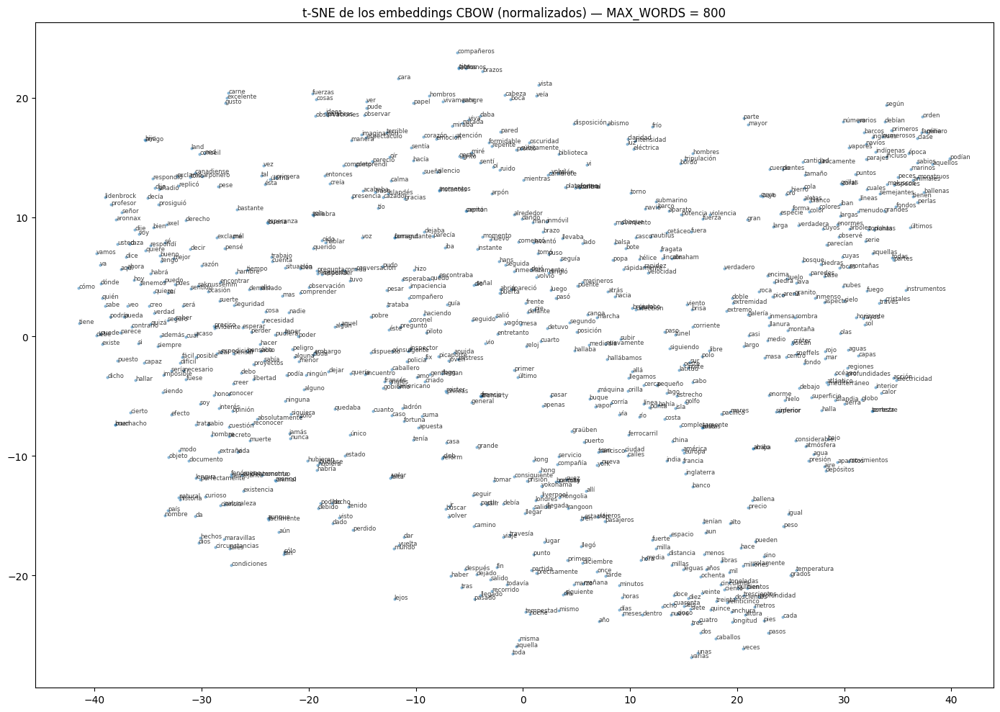

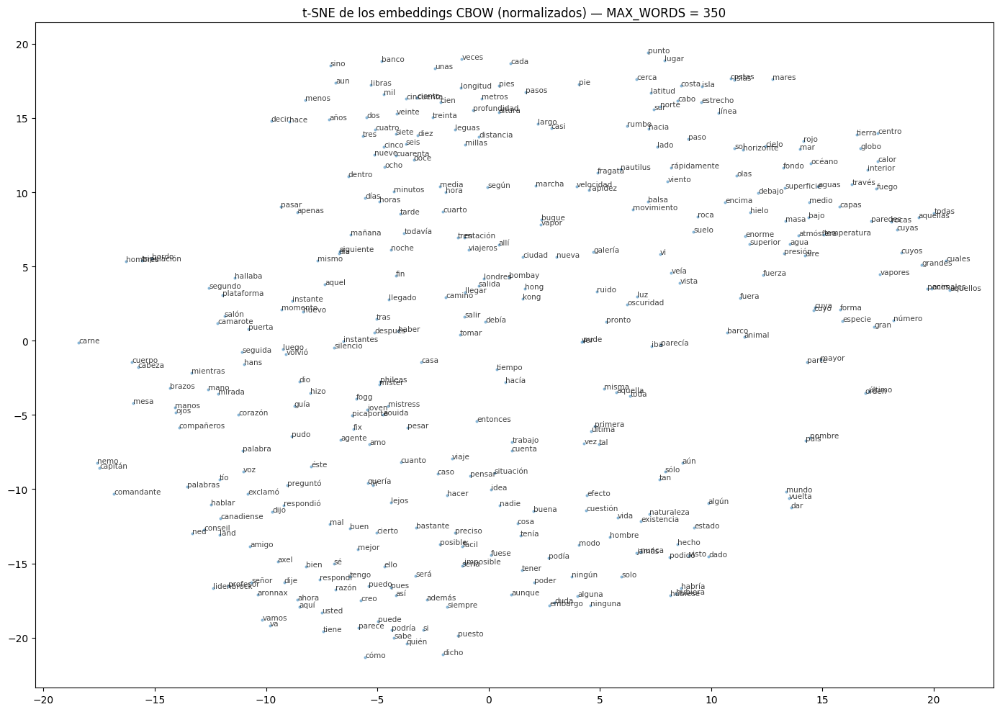

In [15]:
from sklearn.manifold import TSNE

STOPWORDS_ES = set('''de la que el en y a los del se las por un para con no una su al lo como
más pero sus le ya o este sí porque esta entre cuando muy sin sobre también me hasta hay donde
quien desde todo nos durante todos uno les ni contra otros ese eso ante ellos e esto mí antes
algunos qué unos yo otro otras otra él tanto esa estos mucho quienes nada muchos cual poco ella
estar estas algunas algo nosotros mi mis tú te ti tu tus ellas nosotras vosotros vosotras os mío
mía míos mías tuyo tuya tuyos tuyas suyo suya suyos suyas nuestro nuestra nuestros nuestras
vuestro vuestra vuestros vuestras esos esas estoy estás está estamos estáis están esté estés
estemos estéis estén estaré estarás estará estaremos estaréis estarán estaría estarías
estaríamos estaríais estarían estaba estabas estábamos estabais estaban hube hubo era eras
éramos erais eran fui fuiste fue fuimos fuisteis fueron haya he has ha hemos habéis han había
habías habíamos habíais habían es son sea sean ser sido'''.split())

# Modelo para la visualización: CBOW (w=5), el mejor de la sección 5 para palabras frecuentes,
# que son las que se grafican. El skipgram base queda como control de robustez más abajo.
modelo_vis = variantes["CBOW (w=5)"]
palabras_frecuentes = [w for w in modelo_vis.wv.index_to_key if w not in STOPWORDS_ES]

def vectores_normalizados(modelo, palabras):
    # t-SNE usa distancia euclídea; sobre vectores de norma 1 es una función monótona del
    # coseno (||a − b||² = 2 − 2·cos), así la proyección usa la MISMA similitud que el resto
    # del análisis y la norma (que crece con la frecuencia) no distorsiona las distancias.
    return modelo.wv.get_normed_vectors()[[modelo.wv.key_to_index[w] for w in palabras]]

def proyectar_tsne(modelo, palabras, seed=SEED, perplexity=30, init="pca"):
    tsne = TSNE(n_components=2, random_state=seed, init=init, perplexity=perplexity)
    return tsne.fit_transform(vectores_normalizados(modelo, palabras))

proyecciones = {}
for MAX_WORDS in (800, 350):
    sel = palabras_frecuentes[:MAX_WORDS]
    proy = proyectar_tsne(modelo_vis, sel)
    proyecciones[MAX_WORDS] = proy
    fig, ax = plt.subplots(figsize=(14, 10))
    ax.scatter(proy[:, 0], proy[:, 1], s=4, alpha=0.4)
    for (x, y_), w in zip(proy, sel):
        ax.annotate(w, (x, y_), fontsize=6 if MAX_WORDS > 400 else 7.5, alpha=0.75)
    ax.set_title(f"t-SNE de los embeddings CBOW (normalizados) — MAX_WORDS = {MAX_WORDS}")
    plt.tight_layout(); plt.show()

MAX_WORDS = 350
seleccion = palabras_frecuentes[:MAX_WORDS]
proyeccion = proyecciones[MAX_WORDS]  # la misma proyección graficada arriba


**Elección de `MAX_WORDS`:** con 800 palabras las etiquetas se superponen y el gráfico
solo sirve para ver la silueta global; con **350** la gran mayoría de las etiquetas se lee (quedan
superposiciones puntuales, como phileas/mister, que se resuelven en los zooms) y
los grupos se pueden nombrar. Todo el análisis que sigue usa la versión de 350.

In [16]:
# Versión interactiva (plotly) de la misma proyección, para explorar con el mouse
try:
    import plotly.express as px
except ImportError:
    %pip install -q plotly
    import plotly.express as px

fig = px.scatter(x=proyeccion[:, 0], y=proyeccion[:, 1], text=seleccion,
                 title=f"t-SNE interactivo — MAX_WORDS = {MAX_WORDS}")
fig.update_traces(textfont_size=8, marker_size=3)
fig.update_layout(width=950, height=700)
fig.show(renderer="notebook")  # JS de plotly embebido: se ve sin conexión

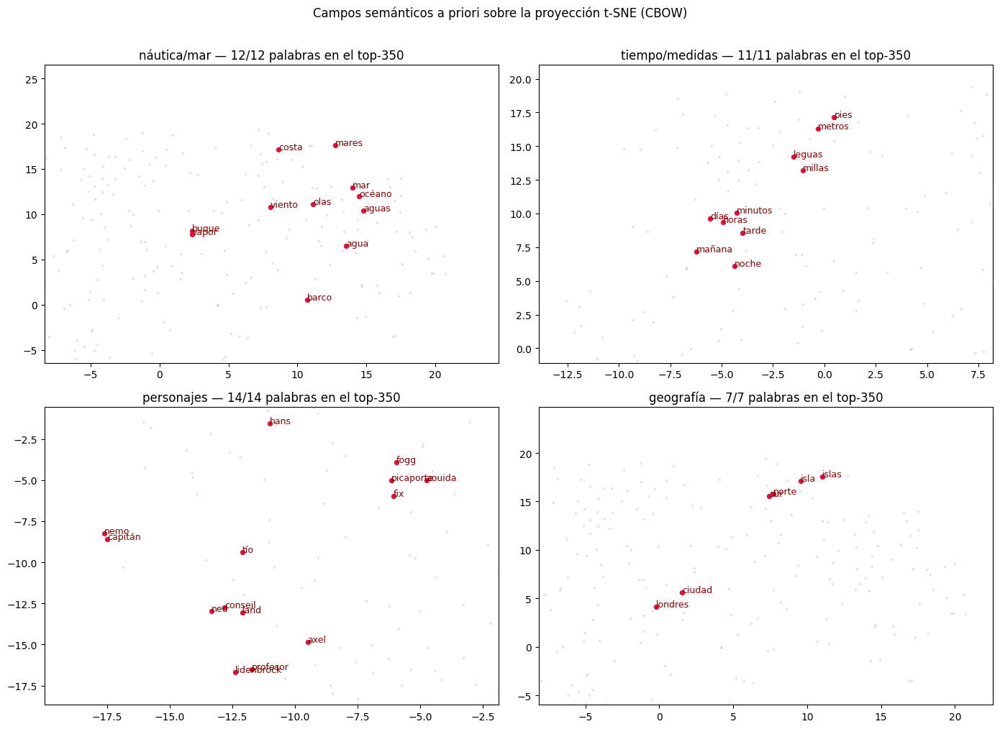

In [17]:
# Zooms por campo semántico: coloreamos grupos de palabras semilla y recortamos la región
# del plano t-SNE que los contiene. Estas figuras estáticas son las "capturas" que pide la
# consigna, embebidas como outputs del notebook.
# (GRUPOS a priori: definidos en la sección 5; los 44 términos están en el top graficado)

pos = {w: proyeccion[i] for i, w in enumerate(seleccion)}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (nombre, palabras) in zip(axes.flat, GRUPOS.items()):
    presentes = [w for w in palabras if w in pos]
    ax.scatter(proyeccion[:, 0], proyeccion[:, 1], s=3, alpha=0.15, color="gray")
    if presentes:
        pts = np.array([pos[w] for w in presentes])
        ax.scatter(pts[:, 0], pts[:, 1], s=18, color="crimson")
        for (x, y_), w in zip(pts, presentes):
            ax.annotate(w, (x, y_), fontsize=9, color="darkred")
        cx, cy = pts.mean(axis=0)
        span = max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1])) / 2 + 1.5  # np.ptp: compatible con NumPy 2
        ax.set_xlim(cx - span, cx + span); ax.set_ylim(cy - span, cy + span)
    ax.set_title(f"{nombre} — {len(presentes)}/{len(palabras)} palabras en el top-{MAX_WORDS}")
plt.suptitle("Campos semánticos a priori sobre la proyección t-SNE (CBOW)", y=1.01)
plt.tight_layout(); plt.show()

#### Exploración: grupos que **descubrimos** en el gráfico

Los cuatro grupos anteriores eran hipótesis *a priori* (verificamos si existían). La consigna pide
además inspeccionar el gráfico y **encontrar** grupos. Recorriendo el t-SNE de 350 palabras del
modelo CBOW aparecen nueve cúmulos que no habíamos propuesto. Los listamos tal como se ven en la
figura y medimos su cohesión con el coseno en el espacio original, contra dos referencias: la
línea de base de pares al azar y un control del sesgo de selección (explicado en el código).

In [18]:
# Grupos que se ven en el t-SNE de 350 palabras (CBOW). Se listan tal como aparecen en la figura.
GRUPOS_EXPLORATORIOS = {
    "números":              ["dos", "tres", "cuatro", "cinco", "seis", "siete", "ocho", "nueve",
                              "diez", "doce", "veinte", "treinta", "cuarenta", "cincuenta", "cien", "mil"],
    "unidades de medida":   ["longitud", "pies", "metros", "profundidad", "altura", "leguas",
                              "distancia", "millas"],
    "tiempo":               ["días", "horas", "minutos", "hora", "tarde", "mañana", "noche", "día"],
    "itinerario de Fogg":   ["estación", "viajeros", "londres", "bombay", "hong", "kong", "tren",
                              "ciudad", "buque", "vapor"],
    "verbos de habla":      ["dijo", "respondió", "exclamó", "preguntó", "dije", "respondí"],
    "física (agua/aire/calor)": ["agua", "aire", "atmósfera", "presión", "temperatura", "masa",
                              "superficie", "capas", "rocas", "calor", "fuego"],
    "cuerpo":               ["cuerpo", "cabeza", "brazos", "mano", "manos", "ojos", "mirada", "corazón"],
    "tiempos compuestos":   ["habría", "hubiera", "hubiese", "podido", "visto", "hecho", "dado"],
    "relativos/demostr.":   ["cuyos", "cuya", "cuyas", "cuales", "aquellos", "aquellas"],
}
pos = {w: proyeccion[i] for i, w in enumerate(seleccion)}
for g, ps in GRUPOS_EXPLORATORIOS.items():
    fuera = [w for w in ps if w not in pos]
    assert not fuera, f"{g}: {fuera} no están en el top-{MAX_WORDS}"

tabla_coh = pd.concat([cohesion(modelo_vis, GRUPOS).assign(origen="a priori"),
                       cohesion(modelo_vis, GRUPOS_EXPLORATORIOS).assign(origen="exploratorio")])
base_azar = linea_base(modelo_vis)
tabla_coh["intra / línea de base"] = tabla_coh["intra"] / base_azar
print(f"línea de base (coseno medio entre pares al azar del top-1000, CBOW): {base_azar:.3f}")

# --- Control del sesgo de selección -------------------------------------------------------
# Los grupos exploratorios se eligieron MIRANDO el t-SNE, es decir, porque ya se veían
# compactos: su cohesión es una cota optimista. Referencia del mismo sesgo: "grupos compactos al
# azar" = un punto al azar del gráfico y sus n−1 vecinos más cercanos EN EL PLANO (el mismo
# criterio visual con el que elegimos los grupos), con el MISMO tamaño n de cada grupo, porque la
# cohesión media depende del tamaño. Un grupo descubierto solo es interesante si su cohesión
# (coseno en el espacio original) supera el p90 de esa referencia.
from sklearn.metrics.pairwise import cosine_similarity as _cos
rng = np.random.default_rng(SEED)
centros = rng.choice(len(seleccion), 300, replace=False)
Vsel = vectores_normalizados(modelo_vis, seleccion)

def p90_compacto(n):
    vals = []
    for c in centros:
        d = np.linalg.norm(proyeccion - proyeccion[c], axis=1)
        idx = np.argsort(d)[:n]
        vals.append(_cos(Vsel[idx])[np.triu_indices(n, k=1)].mean())
    return float(np.percentile(vals, 90))

umbral = {}
for g, ps in GRUPOS_EXPLORATORIOS.items():
    umbral[g] = p90_compacto(len(ps))
tabla_coh["p90 azar compacto (mismo n)"] = tabla_coh["grupo"].map(umbral)
tabla_coh["supera el control"] = np.where(
    tabla_coh["origen"] == "exploratorio",
    (tabla_coh["intra"] > tabla_coh["p90 azar compacto (mismo n)"]).astype(str), "no aplica")

# Hipótesis del narrador: los personajes de las dos novelas narradas en 1.ª persona comparten
# contexto con marcas de 1.ª persona. Coseno medio de cada grupo contra "yo", "me", "dije", "mi".
primera = ["yo", "me", "dije", "mi"]
for nombre_g, pj in [("Viaje al centro (1.ª p.)", ["axel", "lidenbrock", "hans", "tío", "profesor"]),
                     ("Veinte mil leguas (1.ª p.)", ["nemo", "ned", "land", "conseil", "capitán"]),
                     ("La vuelta al mundo (3.ª p.)", ["fogg", "picaporte", "fix", "aouida", "phileas"])]:
    sim = _cos(vectores_normalizados(modelo_vis, pj), vectores_normalizados(modelo_vis, primera)).mean()
    print(f"coseno medio {nombre_g:28s} vs. marcas de 1.ª persona: {sim:.3f}")

tabla_coh.round(3).sort_values(["origen", "intra"], ascending=[False, False]).reset_index(drop=True)


línea de base (coseno medio entre pares al azar del top-1000, CBOW): 0.166


coseno medio Viaje al centro (1.ª p.)     vs. marcas de 1.ª persona: 0.525
coseno medio Veinte mil leguas (1.ª p.)   vs. marcas de 1.ª persona: 0.470
coseno medio La vuelta al mundo (3.ª p.)  vs. marcas de 1.ª persona: 0.067


,grupo,n,intra,inter,margen,origen,intra / línea de base,p90 azar compacto (mismo n),supera el control
0,números,16,0.807,0.250,0.556,exploratorio,4.872,0.630,True
1,unidades de medida,8,0.734,0.286,0.448,exploratorio,4.436,0.693,True
2,verbos de habla,6,0.690,0.019,0.671,exploratorio,4.168,0.729,False
3,tiempo,8,0.642,0.213,0.429,exploratorio,3.880,0.693,False
4,tiempos compuestos,7,0.614,0.067,0.547,exploratorio,3.711,0.708,False
5,cuerpo,8,0.553,0.007,0.546,exploratorio,3.342,0.693,False
6,física (agua/aire/calor),11,0.551,0.142,0.409,exploratorio,3.328,0.661,False
7,itinerario de Fogg,10,0.525,0.153,0.372,exploratorio,3.173,0.678,False
8,relativos/demostr.,6,0.423,0.108,0.315,exploratorio,2.555,0.729,False
9,tiempo/medidas,11,0.512,0.138,0.374,a priori,3.092,NaN,no aplica


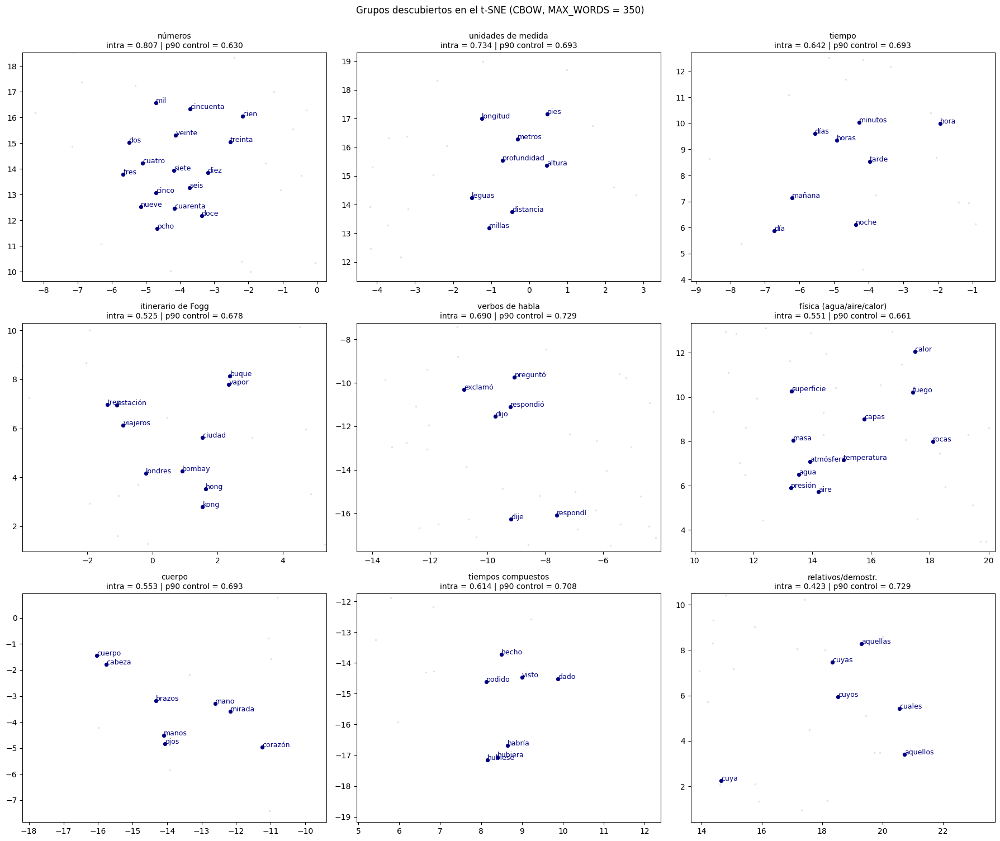

In [19]:
# Captura de los grupos DESCUBIERTOS: mismo tipo de zoom que para los grupos a priori
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
coh_expl = cohesion(modelo_vis, GRUPOS_EXPLORATORIOS).set_index("grupo")
for ax, (nombre, palabras) in zip(axes.flat, GRUPOS_EXPLORATORIOS.items()):
    pts = np.array([pos[w] for w in palabras])
    ax.scatter(proyeccion[:, 0], proyeccion[:, 1], s=3, alpha=0.15, color="gray")
    ax.scatter(pts[:, 0], pts[:, 1], s=18, color="navy")
    for (x, y_), w in zip(pts, palabras):
        ax.annotate(w, (x, y_), fontsize=9, color="navy")
    cx, cy = pts.mean(axis=0)
    span = max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1])) / 2 + 2.0
    ax.set_xlim(cx - span, cx + span); ax.set_ylim(cy - span, cy + span)
    ax.set_title(f"{nombre}\nintra = {coh_expl.loc[nombre, 'intra']:.3f} | p90 control = {umbral[nombre]:.3f}",
                 fontsize=10)
plt.suptitle("Grupos descubiertos en el t-SNE (CBOW, MAX_WORDS = 350)", y=1.0)
plt.tight_layout(); plt.show()


línea de base al azar del espacio skipgram: 0.176
orden de los números por magnitud — CBOW, perp. 30 (analizada)    : |rho de Spearman| = 0.44
orden de los números por magnitud — CBOW, perp. 10                : |rho de Spearman| = 0.48
orden de los números por magnitud — CBOW, perp. 50                : |rho de Spearman| = 0.43
orden de los números por magnitud — CBOW, perp. 30, otra semilla  : |rho de Spearman| = 0.48
orden de los números por magnitud — skipgram base, perp. 30       : |rho de Spearman| = 0.35


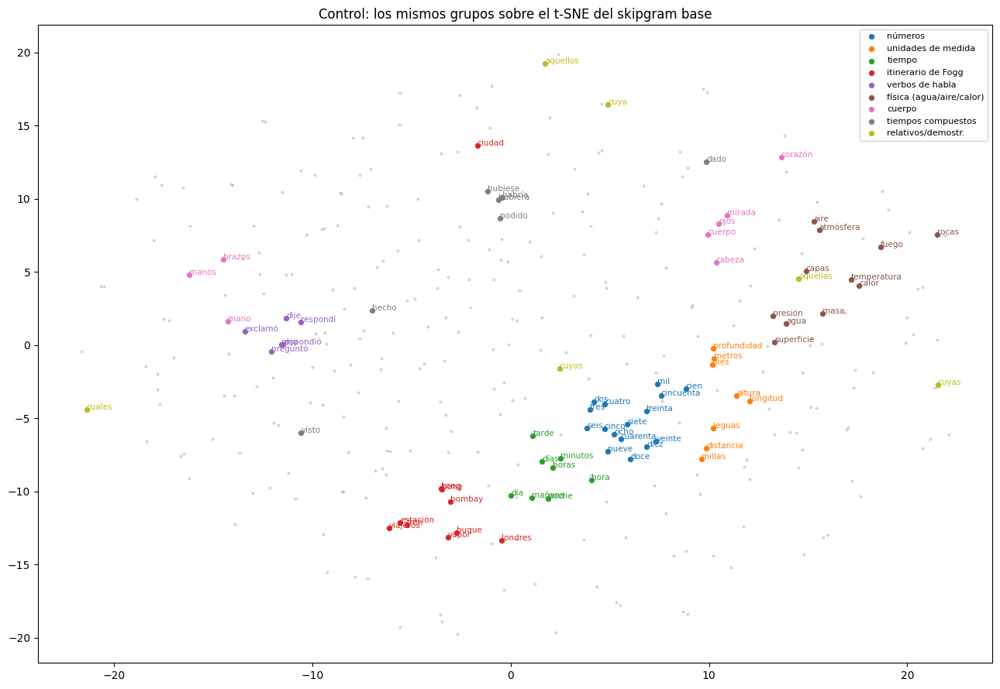

,"CBOW, perp. 30 (analizada)","CBOW, perp. 10","CBOW, perp. 50","CBOW, perp. 30, otra semilla","skipgram base, perp. 30",intra en skipgram (150 dims)
números,0.13,0.14,0.13,0.14,0.16,0.435
unidades de medida,0.11,0.10,0.12,0.12,0.21,0.407
tiempo,0.16,0.17,0.35,0.20,0.14,0.400
itinerario de Fogg,0.16,0.15,0.16,0.47,0.42,0.309
verbos de habla,0.20,0.20,0.22,0.21,0.10,0.453
física (agua/aire/calor),0.19,0.20,0.25,0.24,0.27,0.262
cuerpo,0.14,0.46,0.40,0.39,0.90,0.239
tiempos compuestos,0.11,0.11,0.11,0.11,0.60,0.309
relativos/demostr.,0.22,0.18,0.53,0.58,1.31,0.164


In [20]:
# Robustez: ¿los grupos descubiertos dependen de UNA proyección t-SNE o del modelo elegido?
# Compacidad relativa = distancia 2D media dentro del grupo / distancia 2D media entre las 350
# palabras. < 1 => el grupo queda más junto que el promedio; ~1 => disperso como cualquiera.
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

def compacidad(proy, grupo):
    idx = {w: k for k, w in enumerate(seleccion)}
    return pdist(proy[[idx[w] for w in grupo]]).mean() / pdist(proy).mean()

proyecciones_rob = {
    "CBOW, perp. 30 (analizada)": proyeccion,
    "CBOW, perp. 10": proyectar_tsne(modelo_vis, seleccion, perplexity=10),
    "CBOW, perp. 50": proyectar_tsne(modelo_vis, seleccion, perplexity=50),
    "CBOW, perp. 30, otra semilla": proyectar_tsne(modelo_vis, seleccion, seed=7, init="random"),
    "skipgram base, perp. 30": proyectar_tsne(w2v_model, seleccion),
}
rob = pd.DataFrame({n: {g: round(compacidad(P, ps), 2) for g, ps in GRUPOS_EXPLORATORIOS.items()}
                    for n, P in proyecciones_rob.items()})
rob["intra en skipgram (150 dims)"] = pd.Series({
    g: round(float(_cos(vectores_normalizados(w2v_model, ps))[np.triu_indices(len(ps), k=1)].mean()), 3)
    for g, ps in GRUPOS_EXPLORATORIOS.items()})
print(f"línea de base al azar del espacio skipgram: {linea_base(w2v_model):.3f}")

# ¿Los números están ORDENADOS por magnitud? Spearman entre el valor y la posición a lo largo del
# eje principal del grupo (primera componente PCA de sus 16 puntos), en cada proyección.
valor = {"dos": 2, "tres": 3, "cuatro": 4, "cinco": 5, "seis": 6, "siete": 7, "ocho": 8, "nueve": 9,
         "diez": 10, "doce": 12, "veinte": 20, "treinta": 30, "cuarenta": 40, "cincuenta": 50,
         "cien": 100, "mil": 1000}
idx = {w: k for k, w in enumerate(seleccion)}
for n, P in proyecciones_rob.items():
    pts = P[[idx[w] for w in valor]]
    pts = pts - pts.mean(axis=0)
    eje = np.linalg.svd(pts, full_matrices=False)[2][0]
    rho = spearmanr(list(valor.values()), pts @ eje).correlation
    print(f"orden de los números por magnitud — {n:30s}: |rho de Spearman| = {abs(rho):.2f}")

# t-SNE del skipgram base con los mismos grupos coloreados (control de modelo)
P = proyecciones_rob["skipgram base, perp. 30"]
fig, ax = plt.subplots(figsize=(13, 9))
ax.scatter(P[:, 0], P[:, 1], s=4, alpha=0.25, color="gray")
colores = plt.cm.tab10.colors
for (g, ps), col in zip(GRUPOS_EXPLORATORIOS.items(), colores):
    pts = P[[idx[w] for w in ps]]
    ax.scatter(pts[:, 0], pts[:, 1], s=18, color=col, label=g)
    for (x, y_), w in zip(pts, ps):
        ax.annotate(w, (x, y_), fontsize=7.5, color=col)
ax.legend(fontsize=8, loc="best")
ax.set_title("Control: los mismos grupos sobre el t-SNE del skipgram base")
plt.tight_layout(); plt.show()
rob


**Interpretación de los grupos** (zooms, t-SNE de 350 palabras, tabla de cohesión y pruebas de robustez):

**Grupos a priori (zooms, modelo CBOW).** Los cuatro superan la línea de base de pares al azar
(0,166), de 2,0× a 3,1×.
- **Tiempo/medidas (intra 0,512, el más cohesivo):** se separa en dos regiones, **unidades de
  distancia** (pies, metros, leguas, millas) arriba y **tiempo** (días, horas, minutos, tarde,
  mañana, noche) abajo. El modelo distingue "medir espacio" de "medir tiempo".
- **Geografía (0,418):** **isla, islas, norte, sur** juntas (rumbos y tierras avistadas desde el
  mar) y **londres, ciudad** lejos: cada término se agrupa según la novela que lo usa.
- **Náutica/mar (0,350):** **mar, océano, aguas, olas, mares** forman un núcleo, pero **vapor y
  buque** quedan aparte (son medios de transporte del itinerario de Fogg, ver abajo) y **barco**
  queda más abajo.
- **Personajes (0,338, el menos cohesivo):** se separan **por novela**: fogg, picaporte, fix y
  aouida por un lado; nemo/capitán, ned/land/conseil y lidenbrock/profesor/axel por otro, con hans
  aislado. La tabla
  muestra un detalle interesante: su "inter" es casi 0 (0,007). Los nombres propios casi no se
  parecen a las palabras de los otros campos.

**Grupos descubiertos y control del sesgo de selección.** Como los elegimos *mirando* el gráfico,
su cohesión es una cota optimista. El control mide la cohesión de **grupos compactos al azar del
mismo tamaño** (un punto al azar y sus n−1 vecinos en el plano) y exige superar su p90:
- **Superan el control (estructura fuerte del espacio):**
  - **Números (intra 0,807 contra un p90 de 0,630):** el grupo más cohesivo de todo el notebook,
    4,9× la línea de base. En el gráfico parece haber un orden por magnitud, pero la
    medición **no lo sostiene**: |ρ de Spearman| entre 0,43 y 0,48 en las cuatro proyecciones
    CBOW (0,35 en skipgram), con solo 16 números y sobre un eje elegido a posteriori. Con n=16, un
    ρ de esa magnitud no alcanza significancia al 5% (haría falta |ρ| ≳ 0,5), así que no
    afirmamos ningún orden.
  - **Unidades de medida (0,734 contra 0,693):** longitud, pies, metros, profundidad, altura,
    leguas, distancia, millas.
- **No superan el control.** Se ven agrupados, pero no más que un cúmulo compacto cualquiera de su
  tamaño (en el espacio CBOW, los vecindarios locales ya son muy cohesivos):
  - **Verbos de habla (0,690 contra 0,729):** en el zoom se parten en tercera persona (dijo,
    respondió, exclamó, preguntó) y primera persona (dije, respondí). Esta última queda cerca de
    los narradores Axel y Aronnax en el gráfico general.
  - **Tiempo (0,642 contra 0,693)** y **tiempos compuestos (0,614 contra 0,708):** en el
    zoom, los participios (hecho, podido, visto, dado) arriba y los auxiliares (habría, hubiera,
    hubiese) abajo.
  - **Cuerpo (0,553)**, **física (agua/aire/calor) (0,551)**, **itinerario de Fogg (0,525)** y
    **relativos/demostrativos (0,423)**.

**Hipótesis del narrador, medida.** Los personajes de las dos novelas narradas en **primera
persona** quedan juntos. El coseno medio de cada grupo de personajes contra las marcas de primera
persona (yo, me, dije, mi) es **0,525** (*Viaje al centro*) y **0,470** (*Veinte mil leguas*),
contra **0,067** (*La vuelta al mundo*, narrada en tercera persona). La diferencia es grande y
consistente con la hipótesis, aunque no prueba causalidad.

**Robustez (tabla y figura de control).** La compacidad relativa es la distancia 2D media dentro
del grupo dividida por la distancia media general (menor es más compacto).
- **Números, unidades de medida y tiempos compuestos** quedan compactos (0,10–0,14) con
  perplexity 10, 30 y 50 y con otra semilla de t-SNE. **Cuerpo**, **relativos** e **itinerario de
  Fogg** dependen de la proyección (hasta 0,46, 0,58 y 0,47). Su compacidad en el gráfico analizado es en parte un accidente
  de esa proyección, lo que concuerda con que no superan el control.
- En el **skipgram base**, números, unidades, tiempo y verbos de habla siguen juntos (0,10–0,21).
  En cambio, tiempos compuestos (0,60), cuerpo (0,90) y relativos (1,31) se dispersan: son grupos
  que el modelo CBOW forma y el skipgram no. Lo mismo muestra la figura de control.

**Conclusión de la visualización.** La estructura más fuerte y robusta del espacio está en las
palabras de **cantidad y medida** (números y unidades): superan el control de selección, siguen
compactas con cualquier perplexity y semilla, y aparecen en ambos modelos. Los campos temáticos
a priori superan la línea de base de pares al azar, que es un criterio débil: su cohesión
(0,34–0,51) queda por debajo del p90 de los cúmulos compactos al azar de 6 a 16 palabras (0,63–0,73); es una referencia exigente para grupos que no se eligieron mirando el plano. Además,
esos cuatro grupos se usaron para **elegir** CBOW en la sección 5, así que su buen desempeño acá
no es una validación independiente. Lo que sí muestran los zooms es que se parten según **la
novela que usa cada palabra**: vapor y buque con el viaje de Fogg, y personajes separados por
libro y por tipo de narrador. **Tiempos compuestos** queda compacto en todas las proyecciones CBOW,
pero no supera el control de selección. **Relativos** no supera el control ni es robusto. Por eso
no los contamos como hallazgos.

#### Capturas de los grupos (pegadas en celda de texto, como pide la consigna)

**t-SNE (CBOW) de 350 palabras usado para buscar los grupos:**

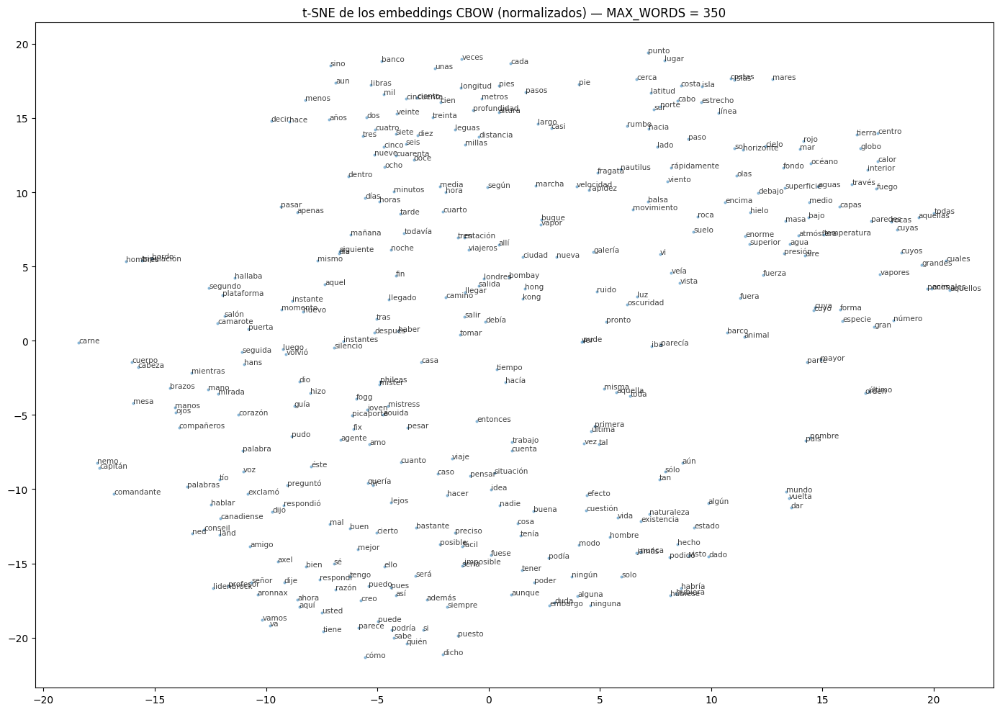

**Zooms de los campos semánticos a priori:**

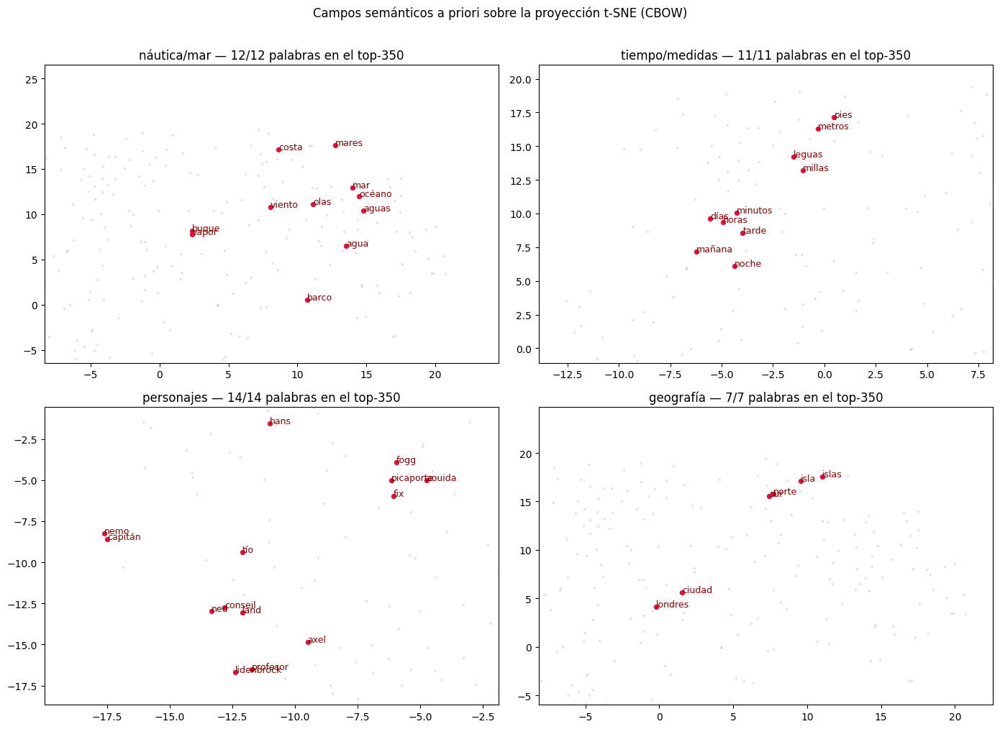

**Zooms de los grupos descubiertos, con su cohesión y el umbral de control:**

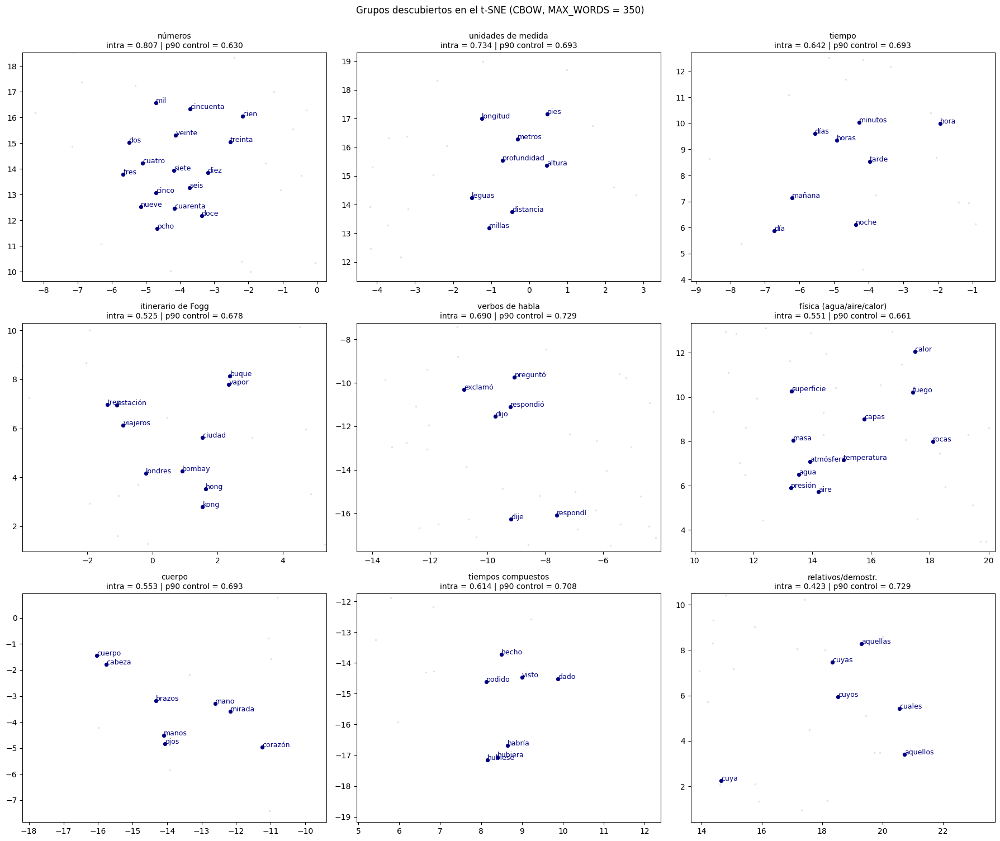

**Control: los mismos grupos sobre el t-SNE del skipgram base:**

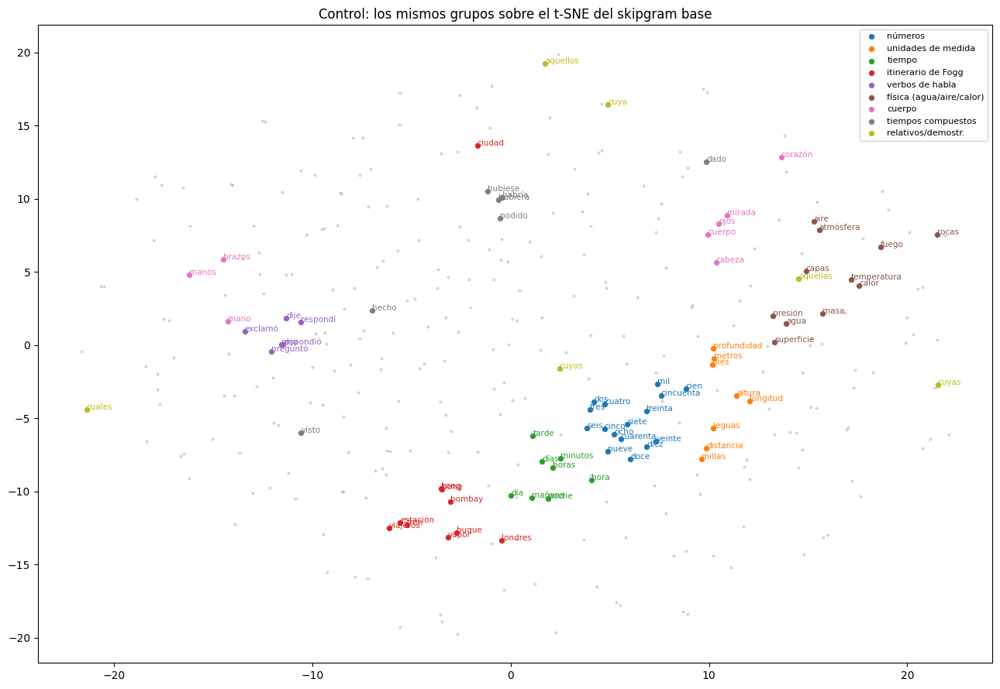



In [21]:
# Visualización 3D interactiva (como en la plantilla), con las mismas palabras y el mismo modelo
proy3 = TSNE(n_components=3, random_state=SEED, init="pca", perplexity=30).fit_transform(
    vectores_normalizados(modelo_vis, seleccion))
grupo_de = {w: g for g, ps in GRUPOS_EXPLORATORIOS.items() for w in ps}
fig = px.scatter_3d(x=proy3[:, 0], y=proy3[:, 1], z=proy3[:, 2], text=seleccion,
                    color=[grupo_de.get(w, "otras") for w in seleccion])
fig.update_traces(marker_size=2, textfont_size=8)
fig.update_layout(width=900, height=700, title="t-SNE 3D (CBOW) — grupos descubiertos coloreados")
fig.show(renderer="notebook")
# resumen numérico para leer el 3D sin interactuar: compacidad de cada grupo también en 3D
print("compacidad relativa en 3D:", {g: round(float(pdist(proy3[[idx[w] for w in ps]]).mean() / pdist(proy3).mean()), 2)
                                     for g, ps in GRUPOS_EXPLORATORIOS.items()})


compacidad relativa en 3D: {'números': 0.28, 'unidades de medida': 0.25, 'tiempo': 0.26, 'itinerario de Fogg': 0.3, 'verbos de habla': 0.27, 'física (agua/aire/calor)': 0.33, 'cuerpo': 0.28, 'tiempos compuestos': 0.25, 'relativos/demostr.': 0.36}


In [22]:
# Exportar vectores y labels en formato tsv para http://projector.tensorflow.org/
# exportamos el modelo de la visualización (CBOW)
vectors = np.asarray(modelo_vis.wv.vectors)
labels = list(modelo_vis.wv.index_to_key)
np.savetxt("vectors.tsv", vectors, delimiter="\t")
with open("labels.tsv", "w", encoding="utf-8") as fp:
    fp.writelines(f"{w}\n" for w in labels)
print(f"Exportados {vectors.shape[0]} vectores de dimensión {vectors.shape[1]} "
      "(vectors.tsv / labels.tsv) para el Embedding Projector.")

Exportados 5242 vectores de dimensión 150 (vectors.tsv / labels.tsv) para el Embedding Projector.


**Lectura del 3D y de la exportación.** En el t-SNE 3D los nueve grupos descubiertos tienen
compacidad relativa entre 0,25 y 0,36, es decir, quedan más juntos que el promedio. Pero ahí no
calculamos una referencia al azar ni probamos otras semillas, así que el 3D es solo una
**vista exploratoria complementaria**, no evidencia adicional: las conclusiones se apoyan en el
análisis 2D, con su control y sus pruebas de robustez. La exportación a
`vectors.tsv` / `labels.tsv` permite explorar el modelo CBOW completo (5.242 palabras) en el
Embedding Projector de TensorFlow, que ofrece PCA y t-SNE interactivos sobre todo el vocabulario.

## Conclusiones generales

1. **Los embeddings toman la forma del corpus.** Los vecinos de `fogg` (mister, phileas, fix,
   picaporte, whist) o de `libras` (gasto, baring, apuesta) reconstruyen la trama de las
   novelas; y `passepartout` ni siquiera existe porque esta traducción lo llama Picaporte. El
   espacio aprendido es un mapa del **uso** de las palabras en estos tres libros, no del español
   en general.
2. **Ninguna configuración gana en todo, y conviene medirlo con varias métricas y semillas.**
   CBOW gana en las palabras frecuentes (cohesión 0,296 contra 0,096, estabilidad 0,531 contra
   0,394). Skipgram es más estable en las raras (0,484 contra 0,427), justo la predicción teórica.
   300 dimensiones da los vecinos más estables en las palabras de frecuencia media y rara, la ventana grande llena los vecindarios de
   stopwords (26,9%), y más épocas favorecen a las palabras raras. Por eso usamos **CBOW para
   visualizar las palabras frecuentes** y dejamos el skipgram como control. Además, ninguna de
   estas decisiones puede basarse en el loss de gensim, que tiene artefactos de precisión
   `float32`.
3. **La estructura más robusta es la de cantidad y medida.** Números y unidades de medida
   superan el control de selección por tamaño, siguen compactos con cualquier perplexity o
   semilla y aparecen en ambos modelos. Los campos temáticos a priori superan la línea de base, pero con cohesión menor que la de los cúmulos compactos del gráfico, y se parten según la novela, y los
   personajes también según el tipo de narrador, con una diferencia medida: coseno 0,47–0,53
   contra las marcas de primera persona, frente a 0,07.
4. **Analogías.** Ambas fallan en el top-5 ("londres" queda 34.º). Para la de los barcos, los
   controles dan un indicio débil de una dirección "barco" (en 2 de 3 barcos; mongolia sube del
   puesto 871 al 167). Las fallas son consistentes con la poca evidencia de los términos
   involucrados (20–64 apariciones) en un corpus de ~258k tokens, frente a los miles de millones
   de los modelos de clase, aunque no lo demostramos.
5. **Limitaciones observadas en los propios outputs:** polisemia fundida en un solo vector
   (`tierra` = tierra firme + interior del planeta), stopwords que se cuelan en vecindarios de
   palabras muy frecuentes, y vocabulario cerrado (`KeyError` ante términos nuevos) — las tres
   motivan lo que sigue en la materia: FastText (n-gramas), embeddings contextuales y el modelo
   por caracteres del Desafío 3.